PHASE 1

In [57]:
# -----------------------------
# Project paths
# -----------------------------

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)

MASTER_DATA_PATH = DATA_DIR / "Master_data_Zuzana.csv"
TWITTER_DATA_PATH = DATA_DIR / "Twitter_Nifty50_Corpus.txt"

In [58]:
# %%
%pip install yfinance scipy matplotlib

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import probplot, kstest, zscore

# -----------------------------
# Parameters
# -----------------------------
start_date = "2019-01-01"
end_date = "2024-12-31"

tickers = {
    "^NSEI": "NIFTY50",
    "^DJI": "DJI",
    "^GDAXI": "DAX",
    "^HSI": "HangSeng",
    "^VIX": "VIX",
    "^N225": "Nikkei" 
}

# -----------------------------
# Function to download and process each ticker
# -----------------------------
def download_index(ticker, label, start, end):
    df = yf.download(ticker, start=start, end=end)

    # flatten MultiIndex if needed
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # keep only Open/Close (or Close for VIX)
    if label == "VIX":
        df = df[["Close"]].rename(columns={"Close": f"{label}_Close"})
    else:
        df = df[["Open", "Close"]].rename(columns={
            "Open": f"{label}_Open",
            "Close": f"{label}_Close"
        })

    # reset index for merging later
    df = df.reset_index()

    # remove Jan 1st each year
    df = df[~((df['Date'].dt.month == 1) & (df['Date'].dt.day == 1))]

    # calculate returns
    #df[f"{label}_Daily_Return"] = df[f"{label}_Close"].pct_change()
    df[f"{label}_Daily_Return"] = df[f"{label}_Close"].pct_change() * 100

    return df

# -----------------------------
# Download all indices
# -----------------------------
all_data = {}
for t, lbl in tickers.items():
    print(f"Downloading {lbl}...")
    all_data[lbl] = download_index(t, lbl, start_date, end_date)

# -----------------------------
# Merge into single DataFrame
# -----------------------------
merged_df = None
for lbl, df in all_data.items():
    if merged_df is None:
        merged_df = df
    else:
        merged_df = merged_df.merge(df, on="Date", how="outer")

# sort by Date
merged_df = merged_df.sort_values("Date").reset_index(drop=True)

# --- Impute missing values (LOCF, then backfill) ---
merged_df = merged_df.fillna(method="ffill").fillna(method="bfill")

/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed

Note: you may need to restart the kernel to use updated packages.



/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed


/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/3949537324.py:77: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  merged_df = merged_df.fillna(method="ffill").fillna(method="bfill")


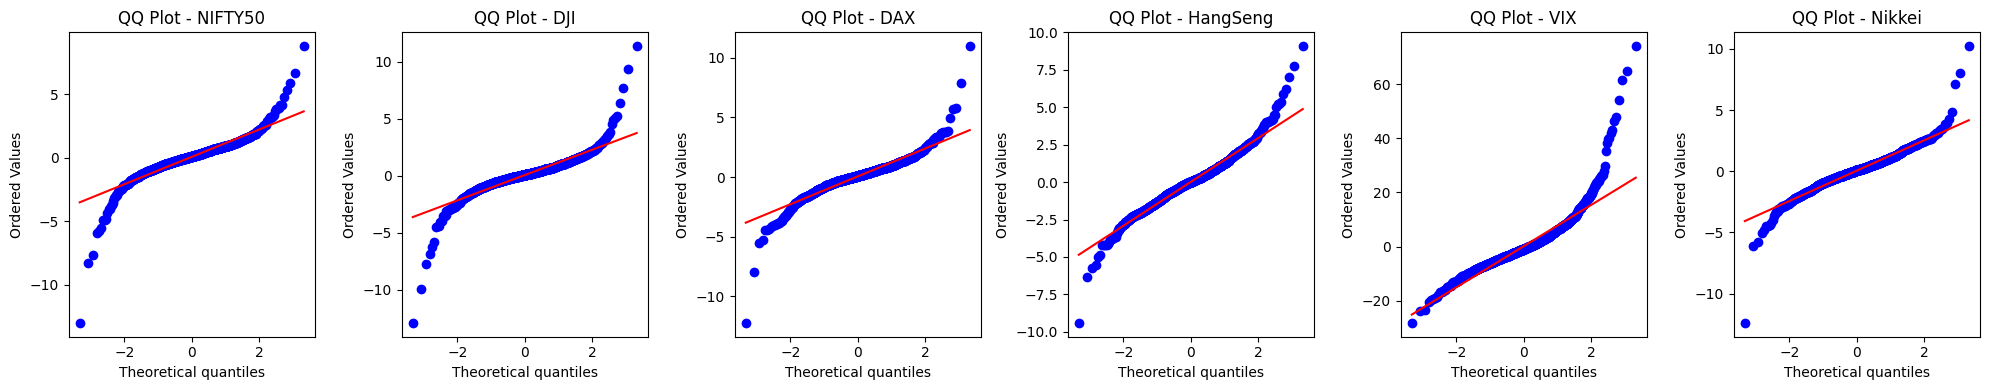

In [59]:
# -----------------------------
# QQ plots
# -----------------------------
returns_data = {
    lbl: merged_df[f"{lbl}_Daily_Return"].dropna()
    for lbl in tickers.values()
}

fig, axes = plt.subplots(1, len(returns_data), figsize=(20, 4))
for ax, (label, data) in zip(axes, returns_data.items()):
    probplot(data, dist="norm", plot=ax)
    ax.set_title(f"QQ Plot - {label}")
plt.tight_layout()
plt.show()


In [60]:
# -----------------------------
# Kolmogorov–Smirnov Test
# -----------------------------
print("Kolmogorov–Smirnov Test Results:")
for label, data in returns_data.items():
    standardized_data = zscore(data)
    stat, p_value = kstest(standardized_data, 'norm')
    print(f"{label}: statistic = {stat:.4f}, p-value = {p_value:.4f}")

# -----------------------------
# Add date features
# -----------------------------
merged_df['quarter'] = merged_df['Date'].dt.quarter
merged_df['month'] = merged_df['Date'].dt.month
merged_df['year'] = merged_df['Date'].dt.year

Kolmogorov–Smirnov Test Results:
NIFTY50: statistic = 0.0920, p-value = 0.0000
DJI: statistic = 0.1111, p-value = 0.0000
DAX: statistic = 0.0966, p-value = 0.0000
HangSeng: statistic = 0.0551, p-value = 0.0001
VIX: statistic = 0.1060, p-value = 0.0000
Nikkei: statistic = 0.0629, p-value = 0.0000


In [61]:
# -----------------------------
# Save final master dataset
# -----------------------------
merged_df.to_csv(MASTER_DATA_PATH, index=False)

print("\nSaved:", MASTER_DATA_PATH)
print("Number of rows:", len(merged_df))


Saved: /Users/zbokova/Desktop/py4e/data/Master_data_Zuzana.csv
Number of rows: 1561


PHASE 2

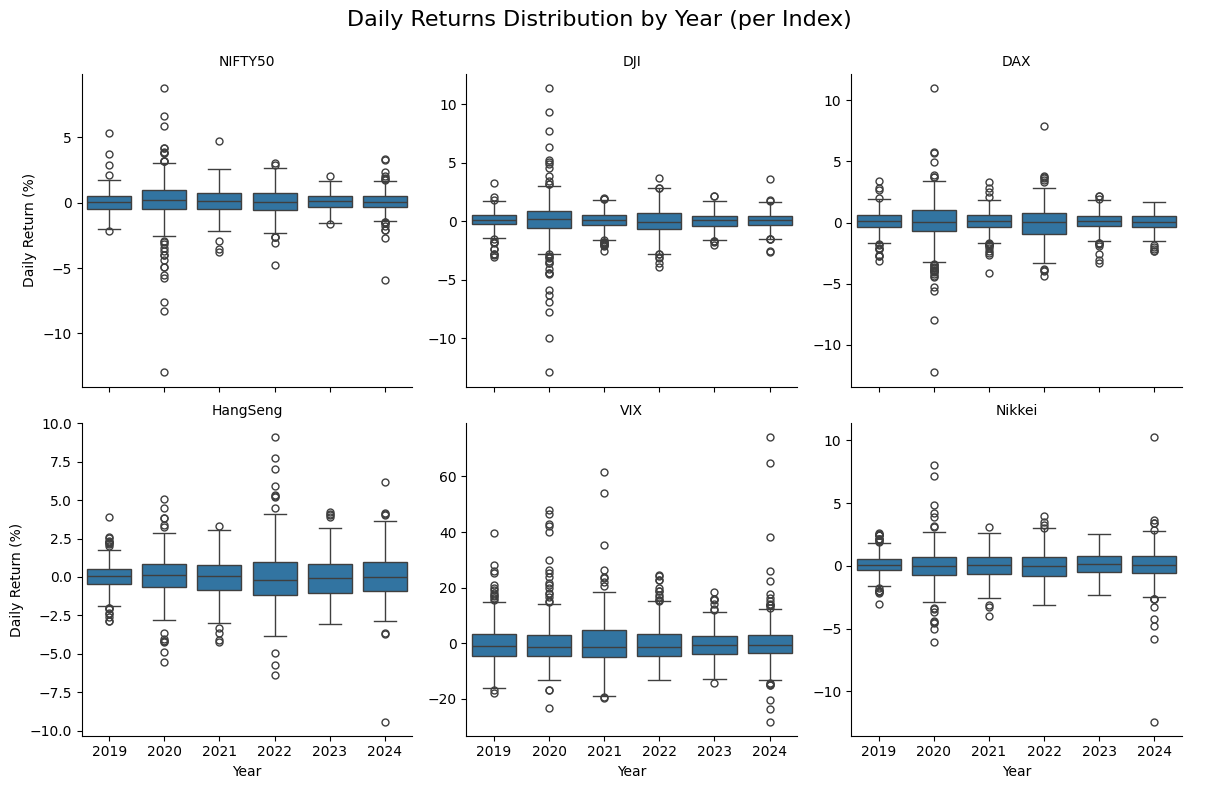

In [62]:
# -----------------------------
# Box whisker plots of daily returns by year
# -----------------------------

import seaborn as sns

df = pd.read_csv(MASTER_DATA_PATH)

# Select only daily return columns
daily_return_cols = [col for col in df.columns if 'Daily_Return' in col]

# Reshape into long format
df_long = df.melt(id_vars=['year'], value_vars=daily_return_cols,
                  var_name='Index', value_name='Daily_Return')

# Clean index names
df_long['Index'] = df_long['Index'].str.replace('_Daily_Return', '')

# ---- Boxplots per index ----
g = sns.catplot(
    data=df_long, x="year", y="Daily_Return",
    col="Index", kind="box", col_wrap=3, height=4, sharey=False
)

g.set_titles("{col_name}")
g.set_axis_labels("Year", "Daily Return (%)")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Daily Returns Distribution by Year (per Index)", fontsize=16)
plt.show()

In [63]:
# -----------------------------
# Table of daily return statistics by year
# -----------------------------

# Get unique indices
indices = df_long['Index'].unique()

# Create a dictionary of summary tables
summary_tables = {}

for idx in indices:
    summary = (
        df_long[df_long['Index'] == idx]
        .groupby('year')['Daily_Return']
        .agg(count='count', mean='mean', std='std')
        .reset_index()
    )
    summary_tables[idx] = summary
    print(f"\nSummary for {idx}:\n", summary)


Summary for NIFTY50:
    year  count      mean       std
0  2019    260  0.059850  0.864243
1  2020    261  0.059507  2.007804
2  2021    260  0.094320  0.982656
3  2022    260  0.054513  1.096428
4  2023    260  0.079254  0.620049
5  2024    260  0.044321  0.867145

Summary for DJI:
    year  count      mean       std
0  2019    260  0.087684  0.804301
1  2020    261  0.055698  2.281591
2  2021    260  0.072774  0.773545
3  2022    260 -0.024515  1.237294
4  2023    260  0.059685  0.708875
5  2024    260  0.051973  0.709076

Summary for DAX:
    year  count      mean       std
0  2019    260  0.077494  0.893303
1  2020    261  0.045306  2.067364
2  2021    260  0.071967  0.900318
3  2022    260 -0.034584  1.460441
4  2023    260  0.082085  0.809460
5  2024    260  0.063841  0.752877

Summary for HangSeng:
    year  count      mean       std
0  2019    260  0.042755  0.965427
1  2020    261  0.027983  1.447279
2  2021    260 -0.029781  1.264380
3  2022    260 -0.020744  2.054467
4  20

/var/folders/41/l2y869890g737crmyx8q_7t40000gn/T/ipykernel_9837/228266122.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


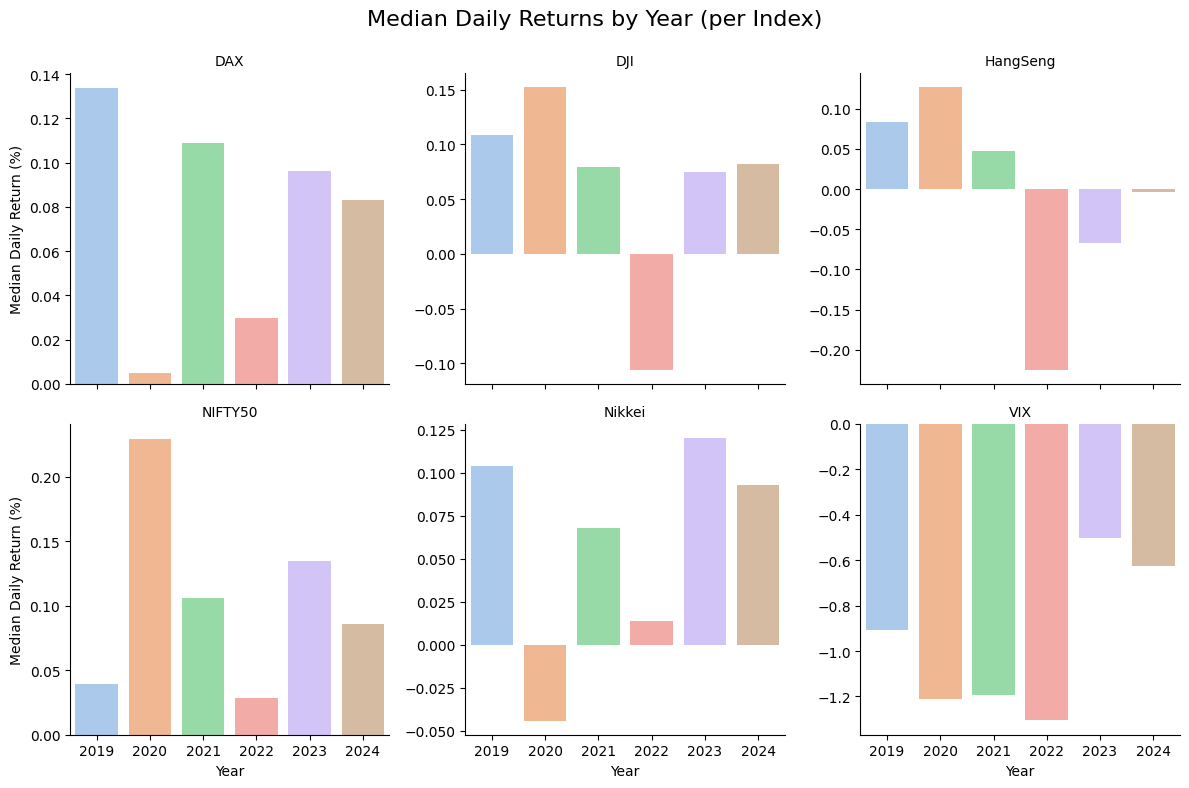

In [64]:
# -----------------------------
# Bar plot of median daily returns by year
# -----------------------------
import matplotlib.pyplot as plt

# Compute median daily returns by year and index
median_df = (
    df_long.groupby(['Index', 'year'])['Daily_Return']
    .median()
    .reset_index()
)

# Bar plot
g = sns.catplot(
    data=median_df,
    x='year',
    y='Daily_Return',
    col='Index',
    kind='bar',
    col_wrap=3,
    height=4,
    sharey=False,
    palette='pastel'
)

g.set_titles("{col_name}")
g.set_axis_labels("Year", "Median Daily Return (%)")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Median Daily Returns by Year (per Index)", fontsize=16)
plt.show()


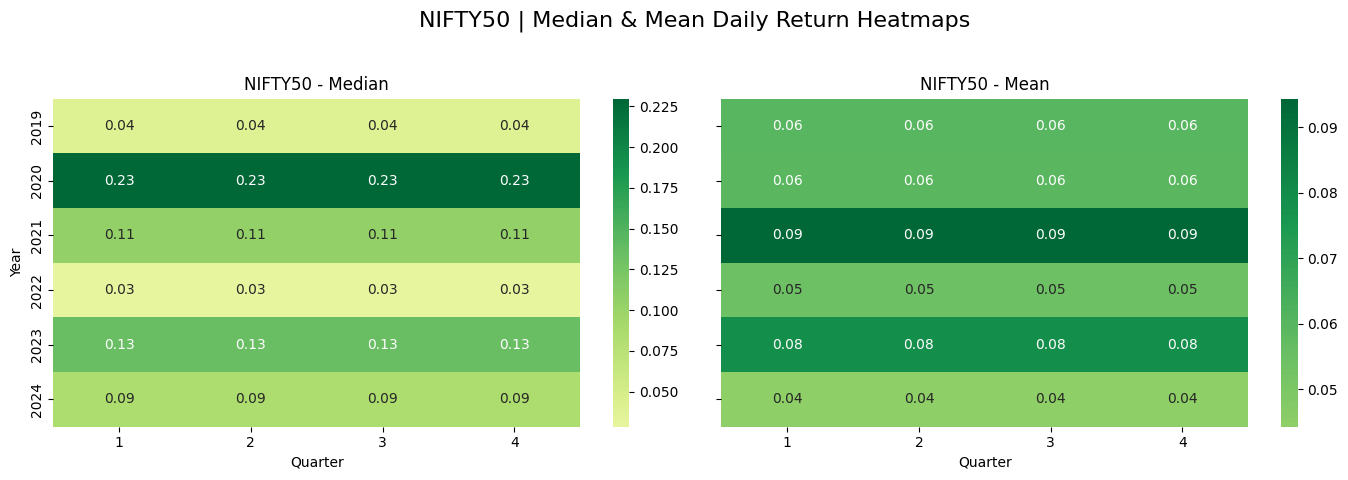

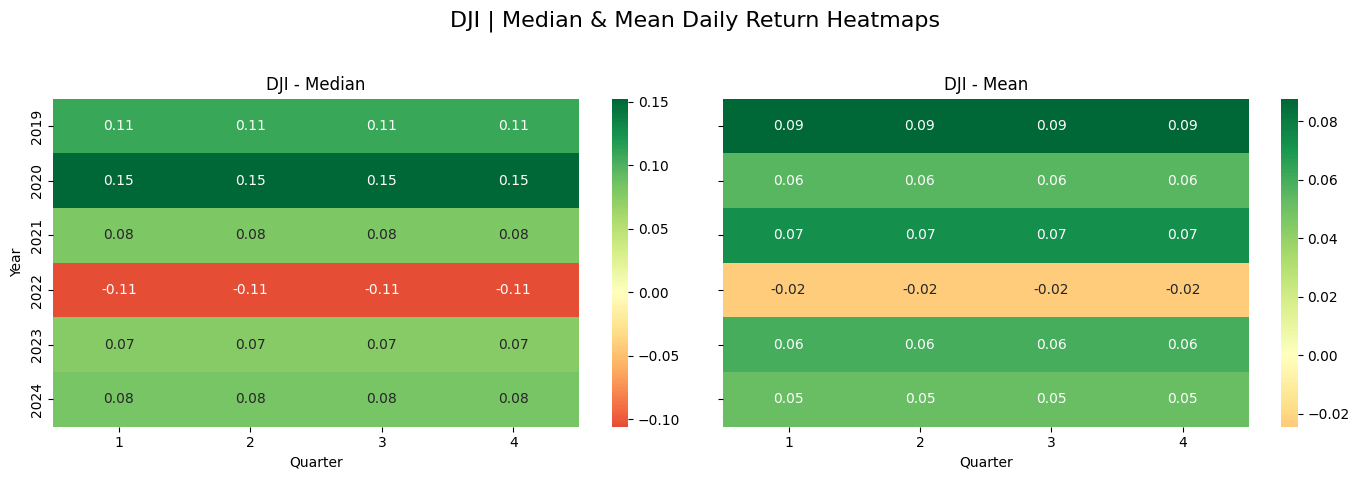

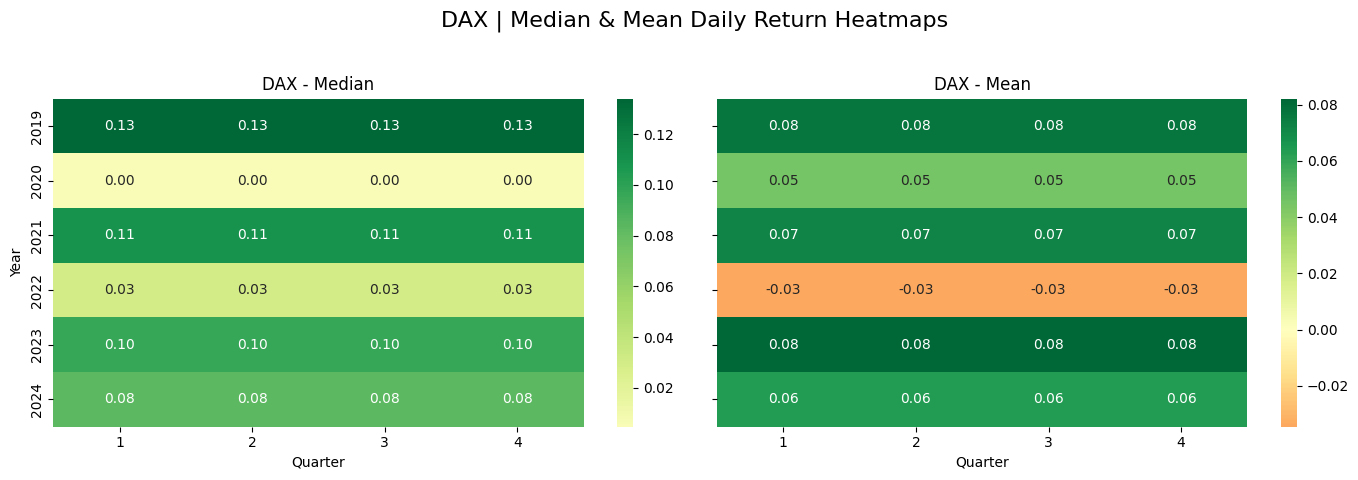

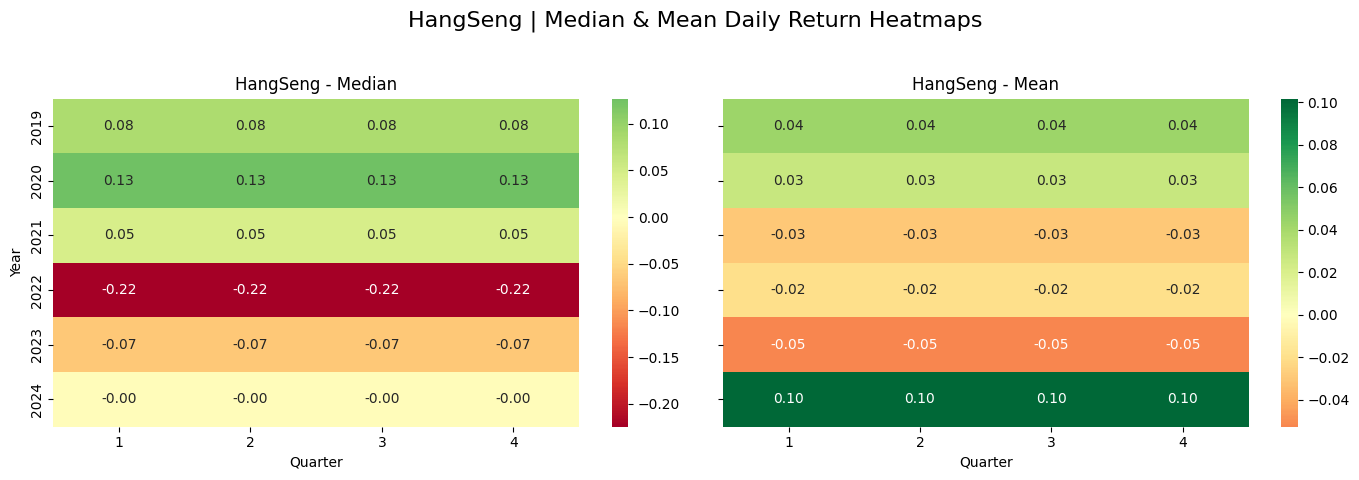

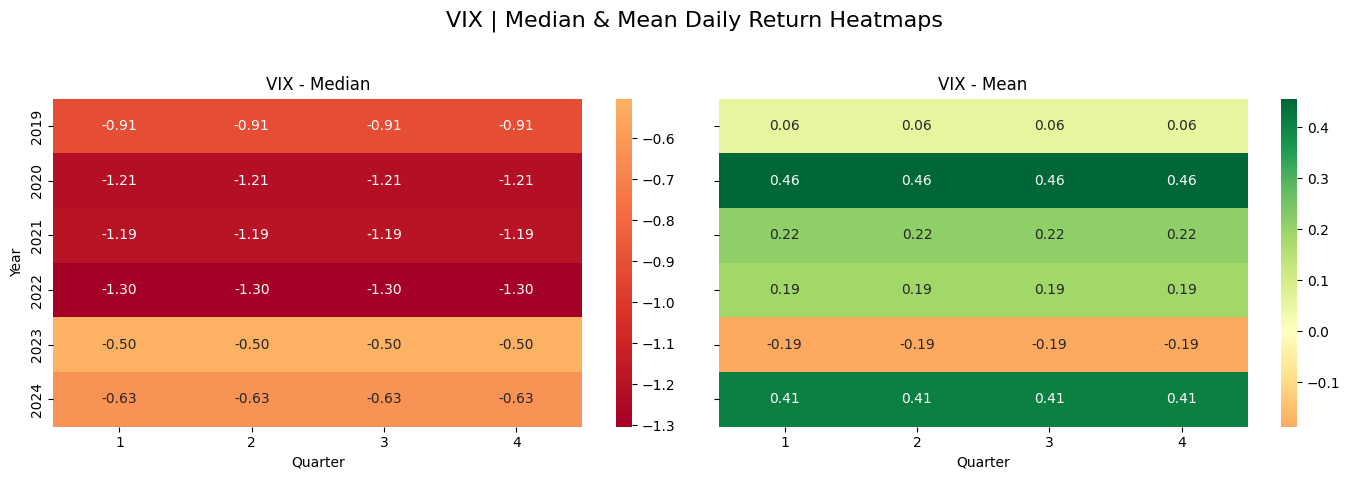

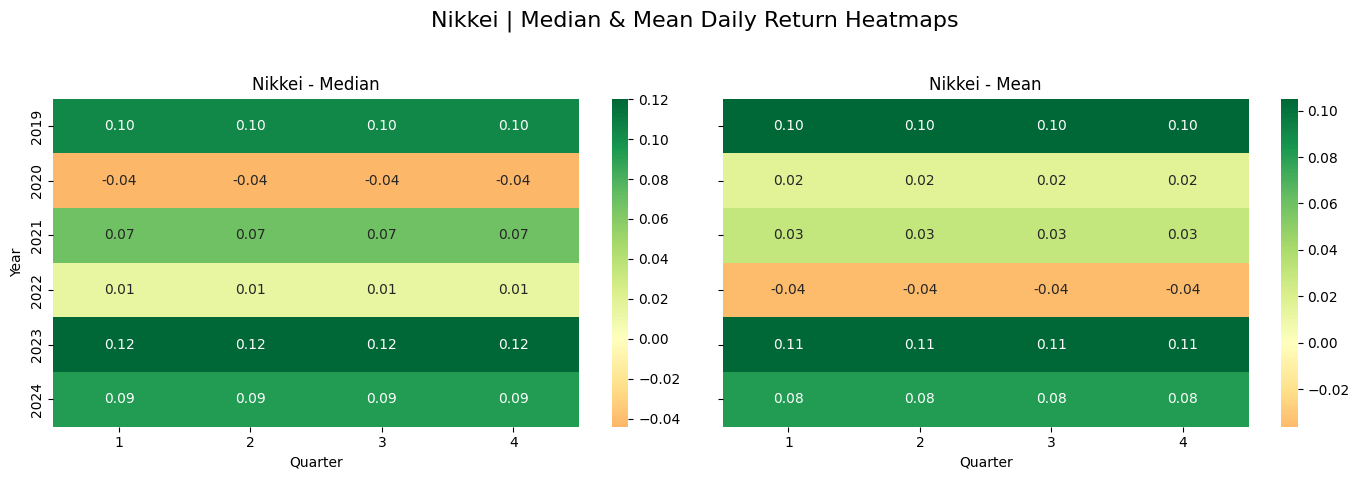

In [65]:
# -----------------------------
# Heat map by "year" and "quarter" showing median/mean returns
# -----------------------------

# Ensure 'quarter' column exists in df_long by merging from merged_df
if 'quarter' not in df_long.columns:
    df_long = df_long.merge(
        merged_df[['Date', 'year', 'quarter']],
        on=['year'],
        how='left'
    )

indices = df_long['Index'].unique()
for idx in indices:
    data = df_long[df_long['Index'] == idx]
    
    # Pivot for median
    median_data = data.pivot_table(index='year', columns='quarter', values='Daily_Return', aggfunc='median')
    # Pivot for mean
    mean_data = data.pivot_table(index='year', columns='quarter', values='Daily_Return', aggfunc='mean')
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    
    sns.heatmap(median_data, annot=True, fmt=".2f", cmap='RdYlGn', center=0, ax=axes[0])
    axes[0].set_title(f"{idx} - Median")
    axes[0].set_ylabel("Year")
    axes[0].set_xlabel("Quarter")
    
    sns.heatmap(mean_data, annot=True, fmt=".2f", cmap='RdYlGn', center=0, ax=axes[1])
    axes[1].set_title(f"{idx} - Mean")
    axes[1].set_ylabel("")
    axes[1].set_xlabel("Quarter")
    
    fig.suptitle(f"{idx} | Median & Mean Daily Return Heatmaps", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    

                       NIFTY50_Daily_Return  DJI_Daily_Return  \
NIFTY50_Daily_Return               1.000000          0.266045   
DJI_Daily_Return                   0.266045          1.000000   
DAX_Daily_Return                   0.410307          0.610290   
HangSeng_Daily_Return              0.338088          0.172638   
VIX_Daily_Return                  -0.191012         -0.644728   
Nikkei_Daily_Return                0.312836          0.223443   

                       DAX_Daily_Return  HangSeng_Daily_Return  \
NIFTY50_Daily_Return           0.410307               0.338088   
DJI_Daily_Return               0.610290               0.172638   
DAX_Daily_Return               1.000000               0.297502   
HangSeng_Daily_Return          0.297502               1.000000   
VIX_Daily_Return              -0.435741              -0.125188   
Nikkei_Daily_Return            0.310745               0.349105   

                       VIX_Daily_Return  Nikkei_Daily_Return  
NIFTY50_Daily_Retu

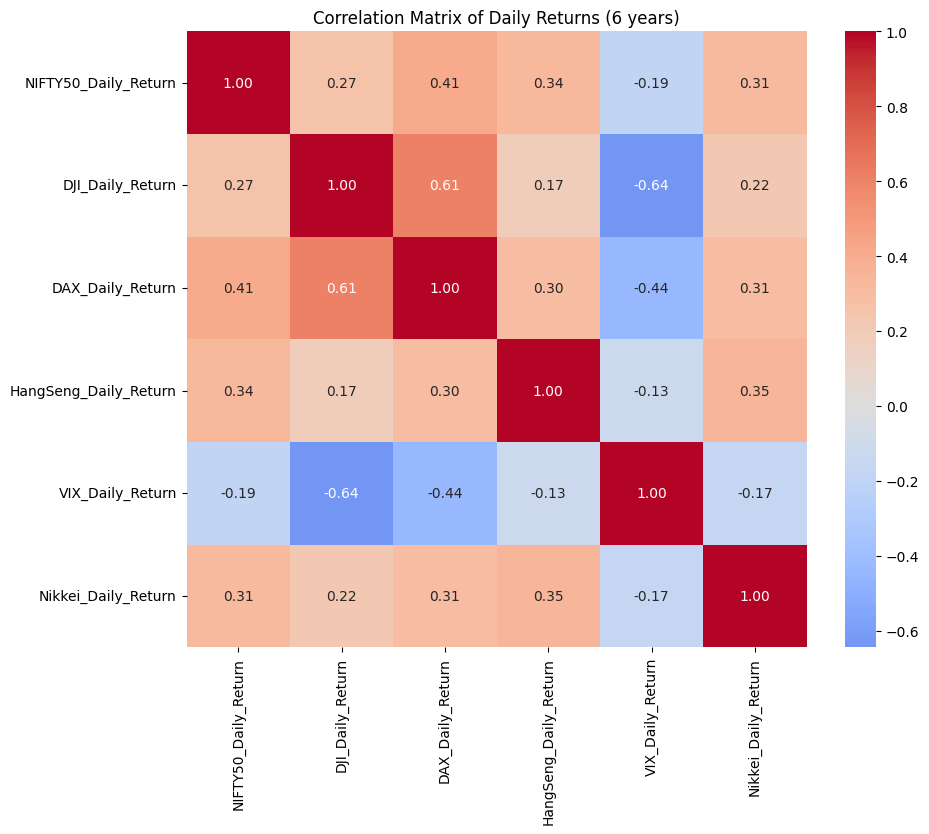

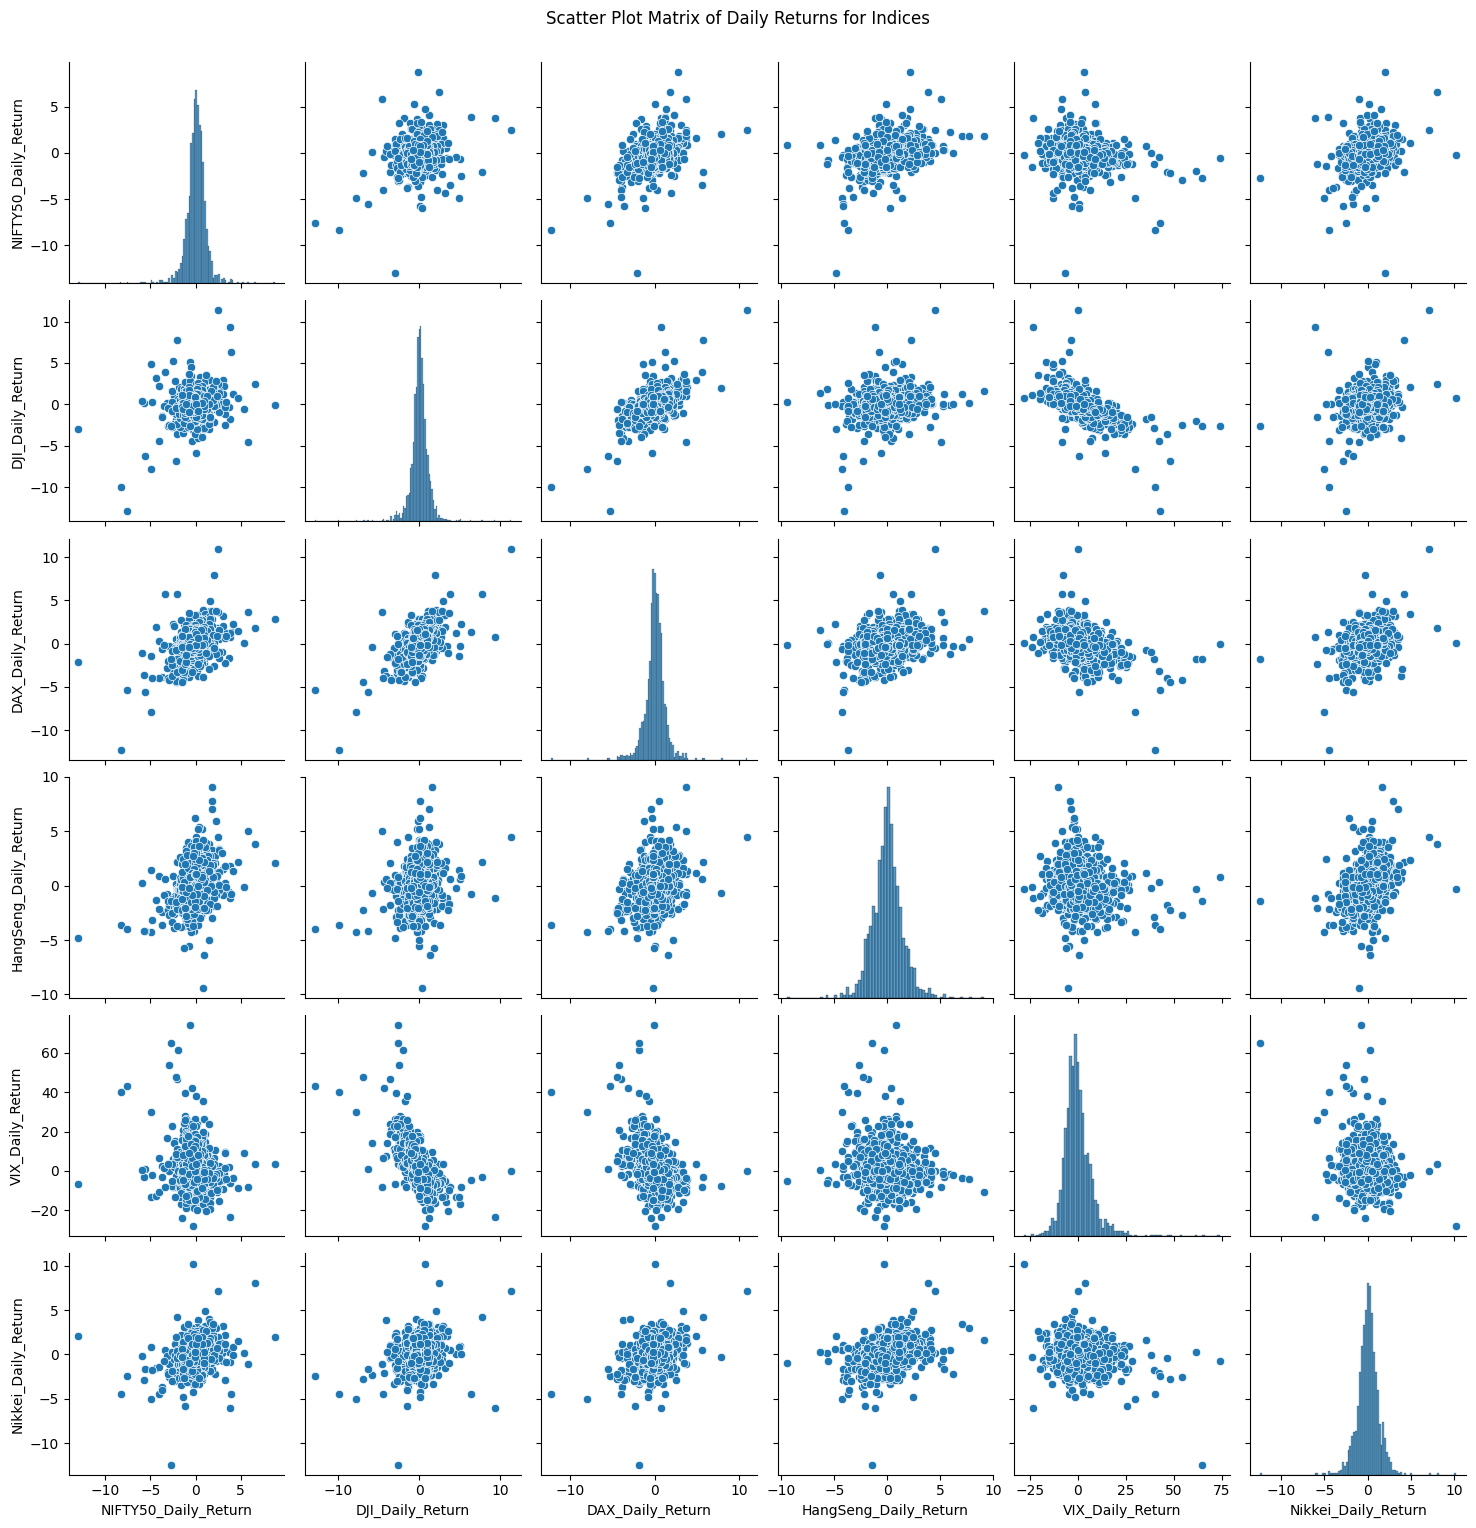

In [66]:
# -----------------------------
# Correlation matrix of daily returns
# -----------------------------
# Select columns with daily returns
daily_return_cols = [col for col in df.columns if 'Daily_Return' in col]

# Filter data for all years present (6 years)
years_of_interest = df['year'].unique()
df_filtered = df[df['year'].isin(years_of_interest)]

# Extract only daily return columns
returns_data = df_filtered[daily_return_cols]

# Calculate correlation matrix
correlation_matrix = returns_data.corr()

# Print correlation matrix
print(correlation_matrix)

# Plot heatmap of correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Correlation Matrix of Daily Returns (6 years)')
plt.show()

# Create pairplot (scatterplot matrix) of daily returns for all indices
sns.pairplot(returns_data)
plt.suptitle('Scatter Plot Matrix of Daily Returns for Indices', y=1.02)
plt.show()

                       NIFTY50_Daily_Return  DJI_Daily_Return  \
NIFTY50_Daily_Return               1.000000          0.149162   
DJI_Daily_Return                   0.149162          1.000000   
DAX_Daily_Return                   0.236829          0.387443   
HangSeng_Daily_Return              0.115854          0.098777   
VIX_Daily_Return                  -0.193729         -0.690199   
Nikkei_Daily_Return                0.274285          0.249232   

                       DAX_Daily_Return  HangSeng_Daily_Return  \
NIFTY50_Daily_Return           0.236829               0.115854   
DJI_Daily_Return               0.387443               0.098777   
DAX_Daily_Return               1.000000               0.241586   
HangSeng_Daily_Return          0.241586               1.000000   
VIX_Daily_Return              -0.303916              -0.094061   
Nikkei_Daily_Return            0.266957               0.129654   

                       VIX_Daily_Return  Nikkei_Daily_Return  
NIFTY50_Daily_Retu

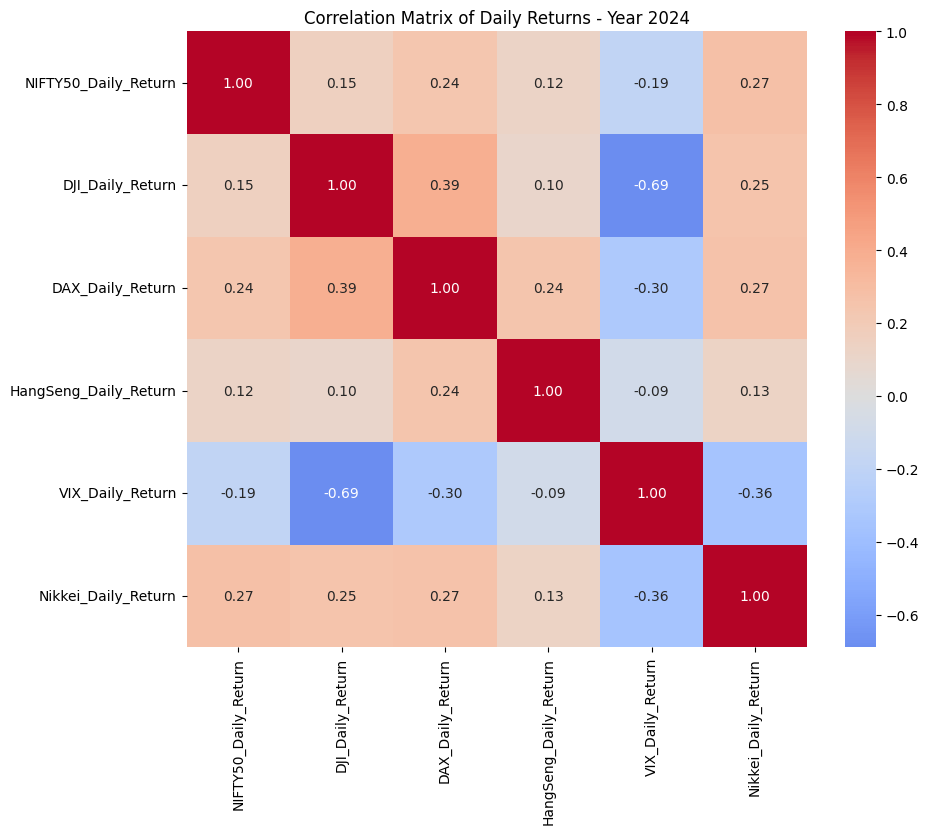

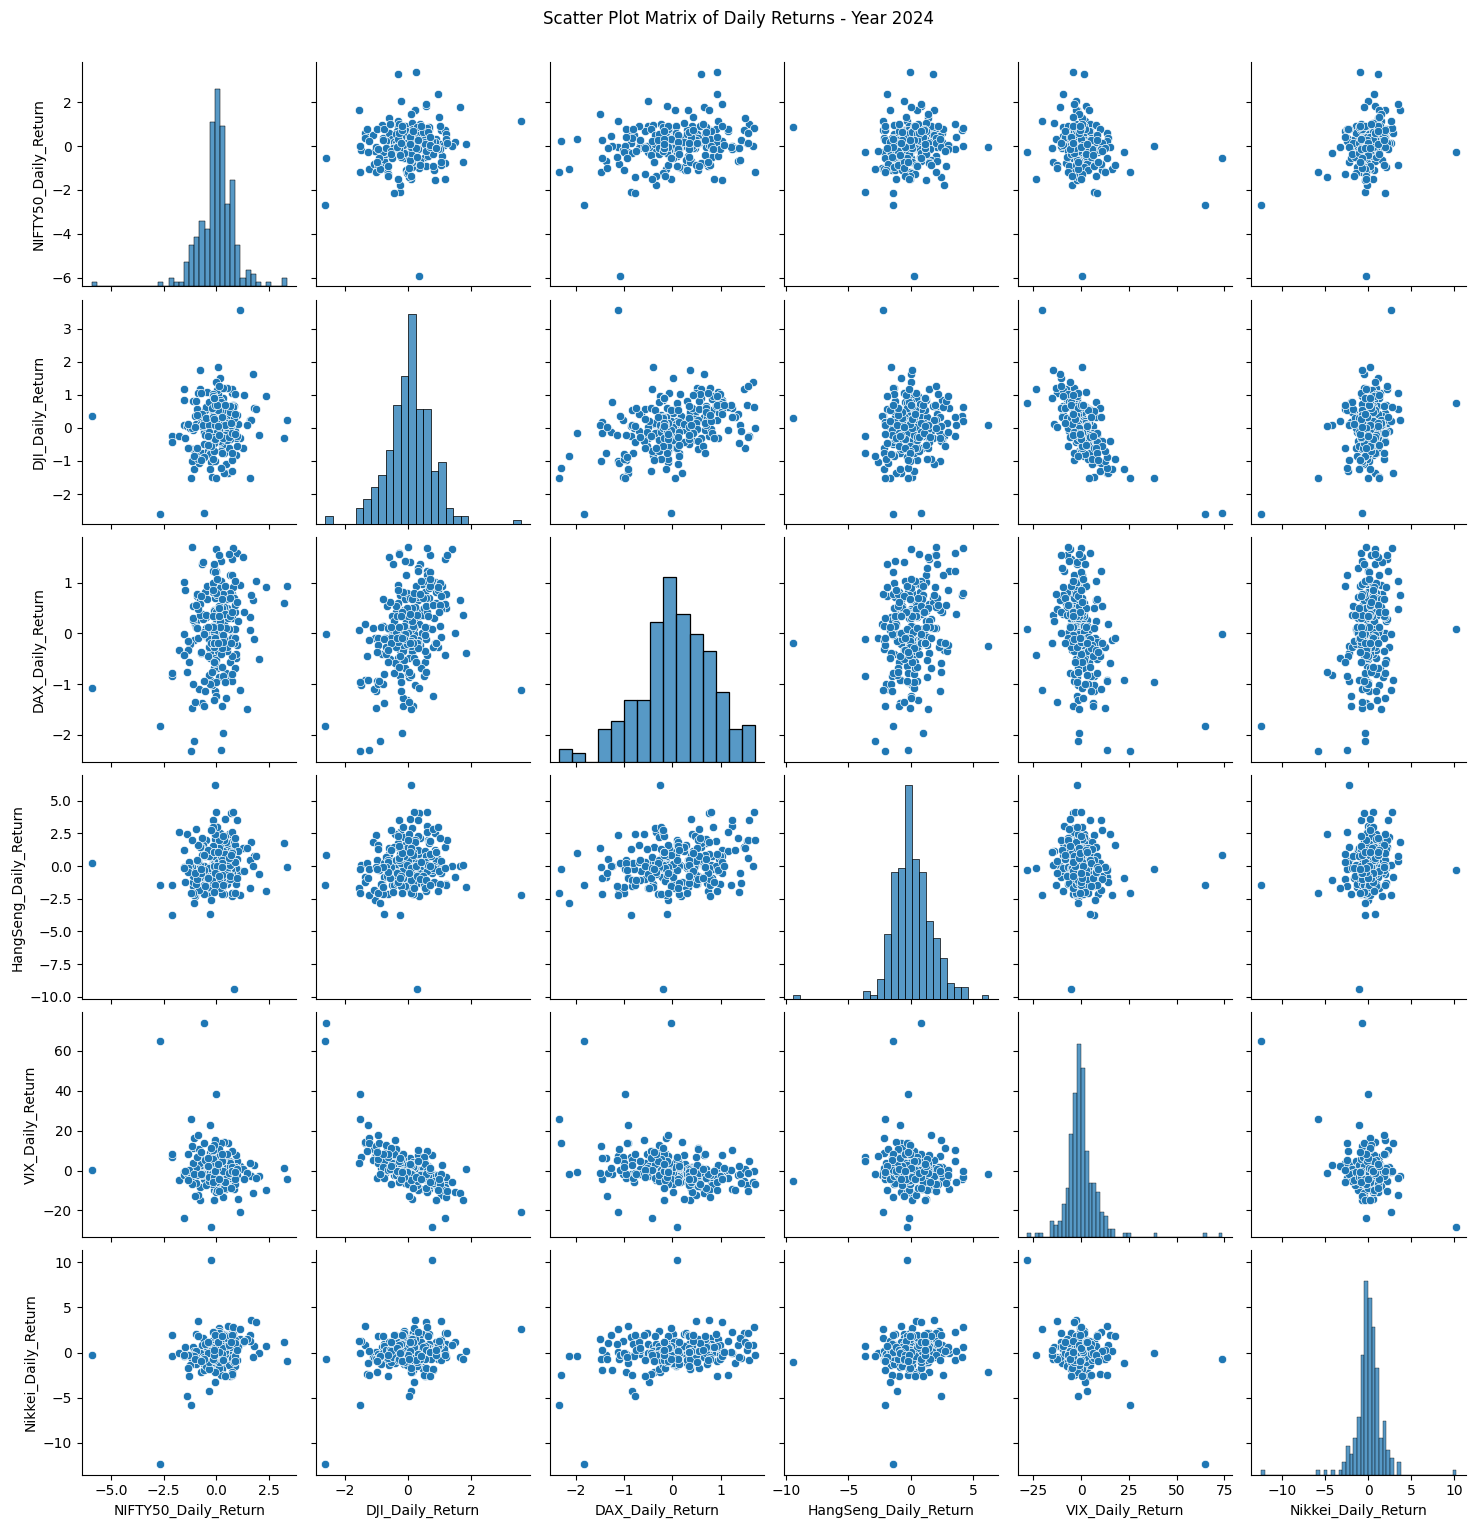

In [67]:
# -----------------------------
# Correlation matrix of year 2024 daily returns
# -----------------------------

# Filter for year 2024
df_2024 = df[df['year'] == 2024]

# Select daily return columns
daily_return_cols = [col for col in df.columns if 'Daily_Return' in col]

# Extract daily returns for 2024
returns_2024 = df_2024[daily_return_cols]

# Calculate correlation matrix for 2024
correlation_2024 = returns_2024.corr()

# Print correlation matrix
print(correlation_2024)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_2024, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Correlation Matrix of Daily Returns - Year 2024')
plt.show()

# Create pairplot scatter matrix
sns.pairplot(returns_2024)
plt.suptitle('Scatter Plot Matrix of Daily Returns - Year 2024', y=1.02)
plt.show()

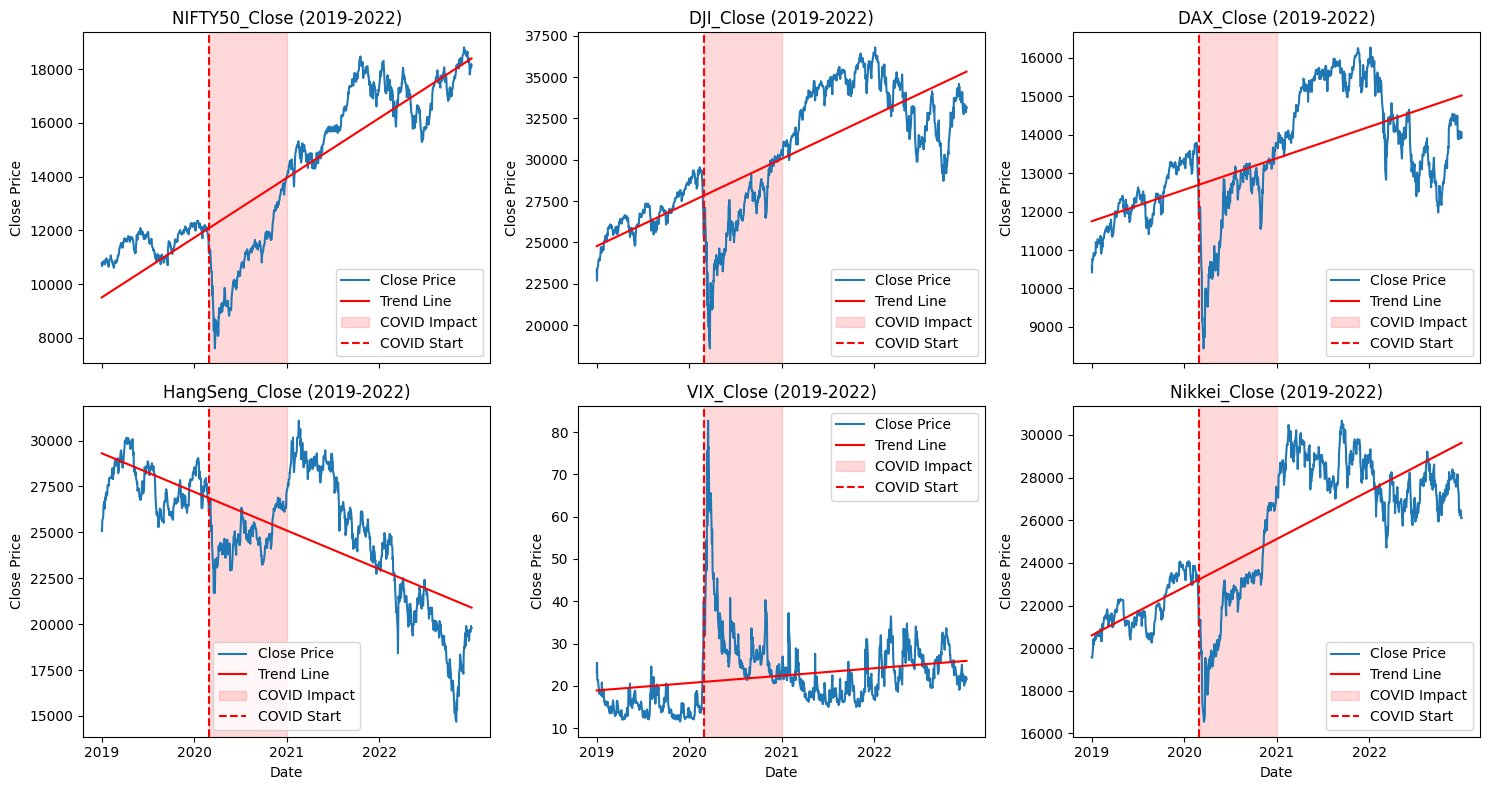

In [68]:
# -----------------------------
# Pre-post COVID analysis (2019-2022)
# -----------------------------
import numpy as np

# Filter for years 2019-2022
df_plot = df[df['year'].between(2019, 2022)].copy()
df_plot['Date'] = pd.to_datetime(df_plot['Date'])
indices_close_cols = [col for col in df_plot.columns if col.endswith('_Close')]

year_start_dates = pd.to_datetime([f'{year}-01-01' for year in range(2019, 2023)])
year_labels = [str(year) for year in range(2019, 2023)]

num_plots = len(indices_close_cols)
cols = 3
rows = (num_plots + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4), sharex=True)
axes = axes.flatten()

for i, col_name in enumerate(indices_close_cols):
    ax = axes[i]
    sns.lineplot(data=df_plot, x='Date', y=col_name, ax=ax, label='Close Price')

    # Add trend line
    x = df_plot['Date'].map(pd.Timestamp.toordinal)
    y = df_plot[col_name]
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    ax.plot(df_plot['Date'], p(x), color="red", label='Trend Line')

    # --- COVID IMPACT VISUALISATION ---
    covid_start = pd.Timestamp('2020-03-01')
    covid_end = pd.Timestamp('2020-12-31')
    ax.axvspan(covid_start, covid_end, color='red', alpha=0.15, label='COVID Impact')
    ax.axvline(covid_start, color='red', linestyle='--', label='COVID Start')

    ax.set_title(f'{col_name} (2019-2022)')
    ax.set_ylabel('Close Price')
    ax.set_xlabel('Date')
    ax.set_xticks(year_start_dates)
    ax.set_xticklabels(year_labels)
    ax.legend()

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [69]:
# -----------------------------
# Nifty 50 Daily movement analysis 
# -----------------------------

# Calculate Nifty_Open_Dir
df['Nifty_Open_Dir'] = (df['NIFTY50_Open'] > df['NIFTY50_Close'].shift(1)).astype(int)

# View the result (first 10 rows)
print(df[['Date', 'NIFTY50_Open', 'NIFTY50_Close', 'Nifty_Open_Dir']].head(10))

         Date  NIFTY50_Open  NIFTY50_Close  Nifty_Open_Dir
0  2019-01-02  10868.849609   10792.500000               0
1  2019-01-03  10796.799805   10672.250000               1
2  2019-01-04  10699.700195   10727.349609               1
3  2019-01-07  10804.849609   10771.799805               1
4  2019-01-08  10786.250000   10802.150391               1
5  2019-01-09  10862.400391   10855.150391               1
6  2019-01-10  10859.349609   10821.599609               1
7  2019-01-11  10834.750000   10794.950195               1
8  2019-01-14  10807.000000   10737.599609               1
9  2019-01-15  10777.549805   10886.799805               1


In [70]:
#--------------
#Table of % of days Nifty opened higher than previous close by year
#--------------

# Aggregate table
result = (
    df.groupby('year')['Nifty_Open_Dir']
      .agg(Total_Trading_Days='count', Positive_Trading_Days='sum')
      .assign(Percent_Nifty_Open_Dir_1 = lambda x: (x['Positive_Trading_Days'] / x['Total_Trading_Days'] * 100).round(2))
      .reset_index()
)

print(result)

   year  Total_Trading_Days  Positive_Trading_Days  Percent_Nifty_Open_Dir_1
0  2019                 260                    179                     68.85
1  2020                 261                    184                     70.50
2  2021                 260                    186                     71.54
3  2022                 260                    154                     59.23
4  2023                 260                    175                     67.31
5  2024                 260                    169                     65.00


In [71]:
# Ensure 'Date' column is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Define weekday and trade type
df['Weekday'] = df['Date'].dt.weekday

def assign_trade_type(d):
    if d == 0:
        return 'Week Open'
    elif d == 4:
        return 'Week Close'
    elif d in [1,2,3]:
        return 'Mid Week'

df['Trade_Type'] = df['Weekday'].apply(assign_trade_type)

# Exclude holidays (if any)
df_filtered = df[df['Trade_Type'] != 'Holiday']

# Summary table grouped by Trade_Type
summary = (
    df_filtered.groupby('Trade_Type')['Nifty_Open_Dir']
    .agg(Total_Trading_Days='count', Positive_Trading_Days='sum')
    .assign(Percent_Nifty_Open_Dir_1=lambda x: (x['Positive_Trading_Days'] / x['Total_Trading_Days'] * 100).round(2))
    .reset_index()
)

print(summary)

   Trade_Type  Total_Trading_Days  Positive_Trading_Days  \
0    Mid Week                 937                    641   
1  Week Close                 312                    206   
2   Week Open                 312                    200   

   Percent_Nifty_Open_Dir_1  
0                     68.41  
1                     66.03  
2                     64.10  


In [72]:
# Map weekday number to names (Monday=0 ... Friday=4)
weekday_map = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday'}
df['Weekday'] = df['Date'].dt.weekday
df = df[df['Weekday'].isin(weekday_map.keys())]  # Filter only Monday-Friday

df['Weekday_Name'] = df['Weekday'].map(weekday_map)

# Group by weekday name and summarize
summary = (
    df.groupby('Weekday_Name')['Nifty_Open_Dir']
      .agg(Total_Trading_Days='count', Positive_Trading_Days='sum')
      .assign(Percent_Nifty_Open_Dir_1=lambda x: (x['Positive_Trading_Days'] / x['Total_Trading_Days'] * 100).round(2))
      .reset_index()
)

# Optional: sort by weekday order
ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
summary['Weekday_Name'] = pd.Categorical(summary['Weekday_Name'], categories=ordered_days, ordered=True)
summary = summary.sort_values('Weekday_Name')

print(summary)


  Weekday_Name  Total_Trading_Days  Positive_Trading_Days  \
1       Monday                 312                    200   
3      Tuesday                 312                    232   
4    Wednesday                 312                    209   
2     Thursday                 313                    200   
0       Friday                 312                    206   

   Percent_Nifty_Open_Dir_1  
1                     64.10  
3                     74.36  
4                     66.99  
2                     63.90  
0                     66.03  


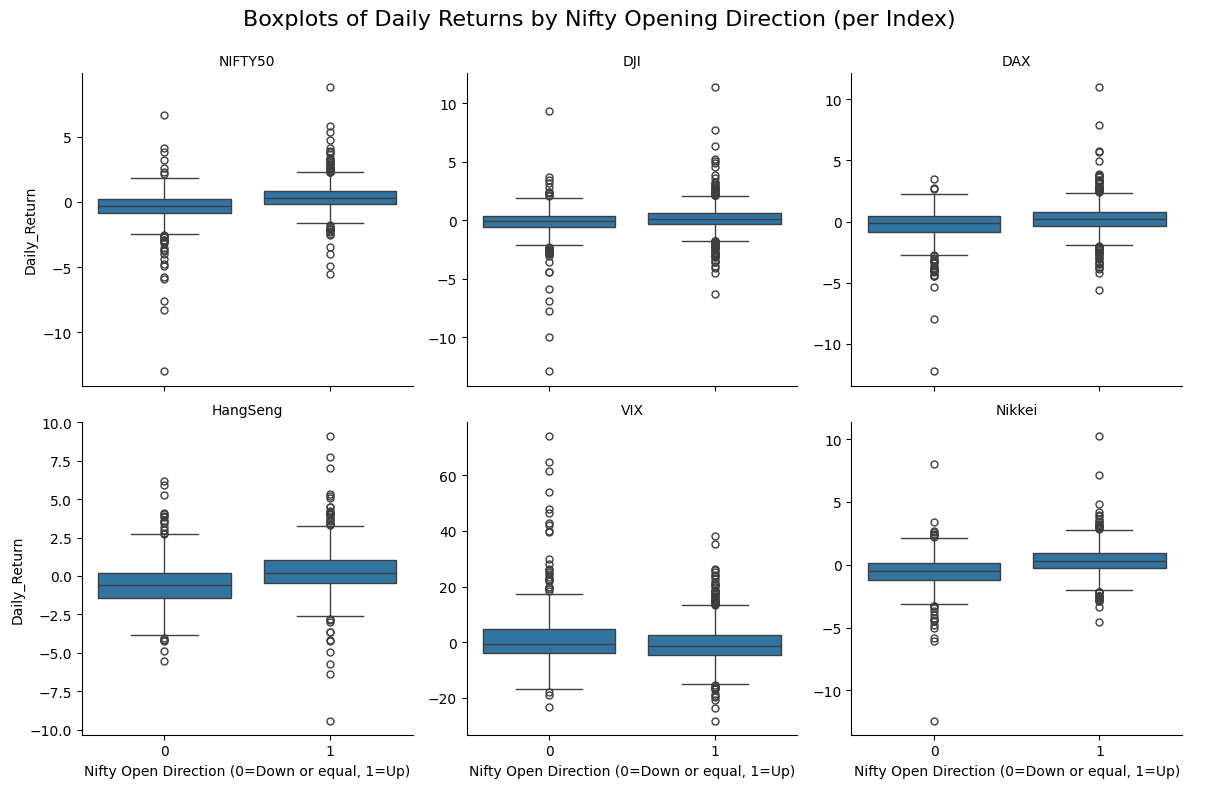

In [73]:
# Select daily return columns
daily_return_cols = [col for col in df.columns if 'Daily_Return' in col]

# Reshape to long format
df_long = df.melt(id_vars=['Nifty_Open_Dir'], value_vars=daily_return_cols,
                  var_name='Index', value_name='Daily_Return')

# Clean up index names
df_long['Index'] = df_long['Index'].str.replace('_Daily_Return', '')

# Create box plots in columns by index
g = sns.catplot(
    data=df_long,
    x='Nifty_Open_Dir',
    y='Daily_Return',
    col='Index',
    kind='box',
    col_wrap=3,
    height=4,
    sharey=False
)

g.set_axis_labels("Nifty Open Direction (0=Down or equal, 1=Up)")
g.set_titles("{col_name}")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Boxplots of Daily Returns by Nifty Opening Direction (per Index)", fontsize=16)
plt.show()

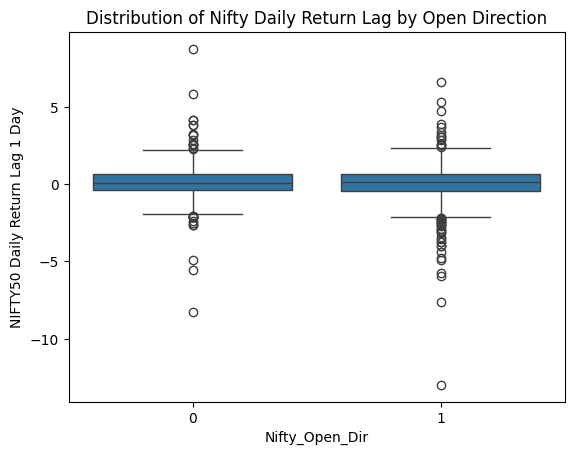

In [74]:
#--------------
# Summary of global indices including VIX for 2 categories of Nifty_Open_Dir
#--------------

# Create lagged return column (previous day's daily return)
df['NIFTY50_Daily_Return_Lag1'] = df['NIFTY50_Daily_Return'].shift(1)

# Plot boxplot of lagged return by Nifty_Open_Dir
sns.boxplot(x='Nifty_Open_Dir', y='NIFTY50_Daily_Return_Lag1', data=df)
plt.xlabel('Nifty_Open_Dir')
plt.ylabel('NIFTY50 Daily Return Lag 1 Day')
plt.title('Distribution of Nifty Daily Return Lag by Open Direction')
plt.show()

In [75]:
#-----------------------------
# Table of indices summary: mean of daily return by Nifty_open_dir
#-----------------------------

# Calculate mean returns per Nifty_Open_Dir
mean_returns = df.groupby('Nifty_Open_Dir')[daily_return_cols].mean().round(4)

# Count days per Nifty_Open_Dir
count_days = df['Nifty_Open_Dir'].value_counts().sort_index()

# Calculate percentage of total days
percent_days = (count_days / count_days.sum() * 100).round(2)

# Combine all in one DataFrame
summary_df = mean_returns.copy()
summary_df['Count_Days'] = count_days
summary_df['Percentage_Days'] = percent_days

# Rename daily return columns for readability
summary_df.rename(columns=lambda x: x.replace('_Daily_Return', ''), inplace=True)

# Reset index to make Nifty_Open_Dir a column
summary_df.reset_index(inplace=True)

print(summary_df)

   Nifty_Open_Dir  NIFTY50     DJI     DAX  HangSeng     VIX  Nikkei  \
0               0  -0.4394 -0.1753 -0.3140   -0.5571  1.5397 -0.6055   
1               1   0.3131  0.1614  0.2302    0.2907 -0.4724  0.3721   

   Count_Days  Percentage_Days  
0         514            32.93  
1        1047            67.07  


PHASE 3

In [76]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [77]:
# Lagged daily returns for predictors
df['DJI_Return_Lag1'] = df['DJI_Daily_Return'].shift(1)
df['DAX_Return_Lag1'] = df['DAX_Daily_Return'].shift(1)
df['HSI_Return_Lag1'] = df['HangSeng_Daily_Return'].shift(1)
df['VIX_Return_Lag1'] = df['VIX_Daily_Return'].shift(1)

print(df[['Date', 'Nifty_Open_Dir', 'DJI_Return_Lag1', 'DAX_Return_Lag1', 'HSI_Return_Lag1', 'VIX_Return_Lag1']].head(10))


        Date  Nifty_Open_Dir  DJI_Return_Lag1  DAX_Return_Lag1  \
0 2019-01-02               0              NaN              NaN   
1 2019-01-03               1        -2.827091        -1.545627   
2 2019-01-04               1        -2.827091        -1.545627   
3 2019-01-07               1         3.292481         3.369893   
4 2019-01-08               1         0.419019        -0.184634   
5 2019-01-09               1         1.088334         0.522626   
6 2019-01-10               1         0.385371         0.826916   
7 2019-01-11               1         0.514260         0.259513   
8 2019-01-14               1        -0.024876        -0.312499   
9 2019-01-15               1        -0.358850        -0.289781   

   HSI_Return_Lag1  VIX_Return_Lag1  
0              NaN              NaN  
1        -0.262592         9.603796  
2        -0.262592         9.603796  
3         2.240911       -15.992147  
4         0.818191         0.093548  
5         0.153857        -4.345796  
6      

In [78]:
#remove the first few rows (with NaNs due to shifting):
model_df = df.dropna(subset=[
    'Nifty_Open_Dir',
    'DJI_Return_Lag1',
    'DAX_Return_Lag1',
    'HSI_Return_Lag1',
    'VIX_Return_Lag1',
    'NIFTY50_Daily_Return_Lag1'
])

In [79]:
#Split into train/test sets (80/20, time-based)
train_size = int(0.8 * len(model_df))
train = model_df.iloc[:train_size]
test = model_df.iloc[train_size:]

In [80]:
#Define features (X) and target (y)
features = [
    'DJI_Return_Lag1',
    'DAX_Return_Lag1',
    'HSI_Return_Lag1',
    'VIX_Return_Lag1',
    'NIFTY50_Daily_Return_Lag1'
]

X_train = train[features]
y_train = train['Nifty_Open_Dir']

X_test = test[features]
y_test = test['Nifty_Open_Dir']


In [81]:
#Fit Binary Logistic Regression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

#Evaluate performance
y_pred = logreg.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.6730769230769231

Confusion Matrix:
 [[ 15  92]
 [ 10 195]]

Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.14      0.23       107
           1       0.68      0.95      0.79       205

    accuracy                           0.67       312
   macro avg       0.64      0.55      0.51       312
weighted avg       0.65      0.67      0.60       312



Accuracy: 0.673 (≈ 67.3%)
The model correctly predicts whether the Nifty 50 opens higher than the previous close at 67,3% of times.


Confusion Matrix:
[[ 15  92]
 [ 10 195]]

- True Negatives (15): Days when Nifty opened lower and model correctly predicted “down.”
- False Positives (92): Days when Nifty opened lower but model incorrectly predicted “up.”
- False Negatives (10): Days when Nifty opened higher but model predicted “down.”
- True Positives (195): Days when Nifty opened higher and model correctly predicted “up.”

The model tends to predict “up” (Nifty opens higher) most of the time — it catches most upward days (recall for class 1 = 0.95), but misses many downward ones (recall for class 0 = 0.14).

The model has high recall for “up” days, meaning it’s very good at identifying when Nifty will open higher.
However, it struggles to identify “down” days — it misclassifies most of them as “up.”
Overall, accuracy of ~67% suggests moderate predictive power, but the imbalance between the two classes limits reliability for predicting downturns.

In [82]:
coef_table = pd.DataFrame({
    'Feature': features,
    'Coefficient': logreg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("\nLogistic Regression Coefficients:")
print(coef_table)


Logistic Regression Coefficients:
                     Feature  Coefficient
0            DJI_Return_Lag1     0.413424
1            DAX_Return_Lag1     0.068787
3            VIX_Return_Lag1    -0.062724
2            HSI_Return_Lag1    -0.074151
4  NIFTY50_Daily_Return_Lag1    -0.292166


| Feature                       | Coefficient | Interpretation                                                                                                                                                                                                     |
| ----------------------------- | ----------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **DJI_Return_Lag1**           | **+0.41**   | A strong positive relationship: when the Dow Jones (US market) performs well on the previous day, the Nifty 50 is **more likely to open higher**. This suggests **global sentiment spillover** from the US market. |
| **DAX_Return_Lag1**           | **+0.07**   | A small positive effect: positive movement in the German DAX slightly increases the probability of Nifty opening higher, reflecting **European influence**.                                                        |
| **HSI_Return_Lag1**           | **−0.07**   | A small negative coefficient: a rise in Hong Kong’s HSI index the previous day slightly decreases the probability of Nifty opening higher, though the effect is weak and might be **statistically insignificant**. |
| **VIX_Return_Lag1**           | **−0.06**   | Negative relationship: higher volatility (VIX increase) tends to **reduce the likelihood** of Nifty opening higher — consistent with the idea that **increased global uncertainty dampens optimism**.              |
| **NIFTY50_Daily_Return_Lag1** | **−0.29**   | Negative coefficient: if Nifty had a strong gain the previous day, it’s **less likely to open higher** the next day, suggesting **short-term mean reversion** or cooling-off effect.                               |

- The model suggests that previous-day movements in major global indices, especially the US (DJI), have a significant influence on Nifty’s opening direction.
- Volatility (VIX) plays a negative role — rising fear/uncertainty tends to suppress bullish openings.
- Nifty’s own lagged return indicates some short-term correction behavior, meaning large gains often lead to a flat or lower open the next day.
- However, the model is biased toward predicting upward openings, indicating potential class imbalance or lack of strong “down-day” signals in the input variables.

In [83]:
#Model diagnostics and validation

#Check Multicollinearity (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Define features used in the logistic regression
features = ['DJI_Return_Lag1', 'DAX_Return_Lag1', 'HSI_Return_Lag1', 
            'VIX_Return_Lag1', 'NIFTY50_Daily_Return_Lag1']

# Compute VIF for each feature
X_vif = df[features].dropna()
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print("Variance Inflation Factor (VIF):")
print(vif_data)


Variance Inflation Factor (VIF):
                     Feature       VIF
0            DJI_Return_Lag1  2.218241
1            DAX_Return_Lag1  1.840127
2            HSI_Return_Lag1  1.169208
3            VIX_Return_Lag1  1.712412
4  NIFTY50_Daily_Return_Lag1  1.283476


Interpretation:
- VIF ≈ 1 → No multicollinearity
- VIF between 5–10 → Moderate multicollinearity
- VIF > 10 → Serious multicollinearity → consider removing or combining correlated variables

All VIF values are below 5, most even close to 1.
This means no multicollinearity problem among your independent variables.
Each feature contributes unique information to the model (not redundant).

In [84]:
#Check Variable Significance (p-values)
import statsmodels.api as sm

# Define X and y (same as before)
X = df[features].dropna()
y = df.loc[X.index, 'Nifty_Open_Dir']

# Add constant for intercept
X_const = sm.add_constant(X)

# Fit logistic regression
logit_model = sm.Logit(y, X_const)
result = logit_model.fit()

# Summary output
print(result.summary())


Optimization terminated successfully.
         Current function value: 0.564247
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:         Nifty_Open_Dir   No. Observations:                 1560
Model:                          Logit   Df Residuals:                     1554
Method:                           MLE   Df Model:                            5
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                  0.1091
Time:                        13:22:55   Log-Likelihood:                -880.23
converged:                       True   LL-Null:                       -988.04
Covariance Type:            nonrobust   LLR p-value:                 1.284e-44
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         0.7983      0.059     13.482      0.000       0.

Interpretation:
- Pseudo R² = 0.1091 → The model explains ~10.9% of the variation in the dependent variable.
That’s typical for financial data, where daily movements are hard to predict.
- LLR p-value = 1.284e-44 → Model is statistically significant overall.

| Variable                      | Coefficient | p-value   | Interpretation                                                                                                                            |
| ----------------------------- | ----------- | --------- | ----------------------------------------------------------------------------------------------------------------------------------------- |
| **const**                     | 0.7983      | 0.000     | Positive constant; baseline probability > 0.5 when all predictors = 0                                                                     |
| **DJI_Return_Lag1**           | **0.5065**  | **0.000** | Strong, positive, and **significant** — when Dow Jones rises the previous day, Nifty is more likely to open higher.                       |
| **DAX_Return_Lag1**           | 0.0488      | 0.476     | **Not significant** — European (German) market doesn’t have a statistically strong effect on Nifty’s next open.                           |
| **HSI_Return_Lag1**           | -0.0663     | 0.118     | Weak negative relationship, but **not significant** (p > 0.05).                                                                           |
| **VIX_Return_Lag1**           | **-0.0557** | **0.000** | **Significant and negative** — higher volatility (VIX) reduces the probability of Nifty opening higher.                                   |
| **NIFTY50_Daily_Return_Lag1** | **-0.2308** | **0.000** | **Significant and negative** — when Nifty rose yesterday, it’s slightly less likely to open higher again today (possible mean reversion). |


1. Significant predictors:
- DJI_Return_Lag1 (positive impact)
- VIX_Return_Lag1 (negative impact)
- NIFTY50_Daily_Return_Lag1 (negative impact)

All p < 0.05.

2. Insignificant predictors:
- DAX_Return_Lag1 (p = 0.476)
- HSI_Return_Lag1 (p = 0.118)

3. Economic intuition fits well:
- Nifty tends to follow positive U.S. sentiment (DJI).
- High volatility (VIX up) discourages upward openings.
- Mean reversion pattern visible in its own lagged return.

In [85]:
#Dropping insignificant variables and Re-running the logistic regression

# Define significant features
significant_features = ['DJI_Return_Lag1', 'VIX_Return_Lag1', 'NIFTY50_Daily_Return_Lag1']

# Drop missing values
X_sig = df[significant_features].dropna()
y_sig = df.loc[X_sig.index, 'Nifty_Open_Dir']

# Add constant
X_sig_const = sm.add_constant(X_sig)

# Fit logistic regression
logit_model_sig = sm.Logit(y_sig, X_sig_const)
result_sig = logit_model_sig.fit()

# Show summary
print(result_sig.summary())


Optimization terminated successfully.
         Current function value: 0.565118
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:         Nifty_Open_Dir   No. Observations:                 1560
Model:                          Logit   Df Residuals:                     1556
Method:                           MLE   Df Model:                            3
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                  0.1077
Time:                        13:22:55   Log-Likelihood:                -881.58
converged:                       True   LL-Null:                       -988.04
Covariance Type:            nonrobust   LLR p-value:                 6.845e-46
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         0.7982      0.059     13.497      0.000       0.

| Metric             | Value     | Interpretation                                                               |
| :----------------- | :-------- | :--------------------------------------------------------------------------- |
| **Log-Likelihood** | -881.58   | Higher (less negative) than before (-880.23 → -881.58, similar fit).         |
| **Pseudo R²**      | 0.1077    | Model explains ~10.8% of variation — typical for financial direction models. |
| **LLR p-value**    | 6.845e-46 | Extremely small → model is **highly statistically significant** overall.     |
| **Iterations**     | 6         | Model converged normally → stable estimation.                                |


In [86]:
#Predict probabilities and compute ROC metrics

from sklearn.metrics import roc_curve, auc

# Predicted probabilities for positive class (Nifty opens up)
y_pred_prob = result_sig.predict(X_sig_const)

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_sig, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Display AUC
print(f"AUC (Train Data): {roc_auc:.3f}")


AUC (Train Data): 0.744


AUC 0.744 -> The model correctly distinguishes between “up” and “down” openings about 74.4% of the time — substantially better than random guessing (50%).

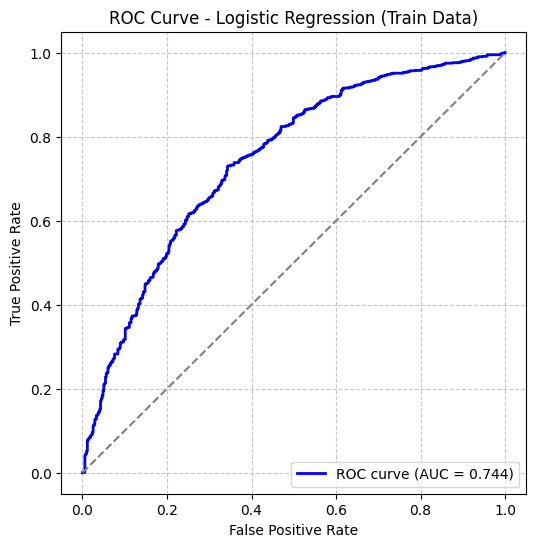

In [87]:
#ROC Curve plot
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression (Train Data)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


In [88]:
#Compute optimal threshold
from sklearn.metrics import roc_curve, roc_auc_score

# Predict probabilities for the positive class (1)
y_pred_prob = result_sig.predict(X_sig_const)

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_sig, y_pred_prob)

# Compute the point where sensitivity ≈ specificity
# That is, where |tpr - (1 - fpr)| is minimized
balance_index = np.argmin(np.abs(tpr - (1 - fpr)))
optimal_threshold = thresholds[balance_index]

# Print the results
print(f"Optimal Threshold (Sensitivity ≈ Specificity): {optimal_threshold:.3f}")
print(f"Sensitivity (TPR): {tpr[balance_index]:.3f}")
print(f"Specificity (1 - FPR): {1 - fpr[balance_index]:.3f}")
print(f"AUC: {roc_auc_score(y_sig, y_pred_prob):.3f}")


Optimal Threshold (Sensitivity ≈ Specificity): 0.679
Sensitivity (TPR): 0.681
Specificity (1 - FPR): 0.678
AUC: 0.744


The optimal probability threshold for classifying whether the Nifty opens higher than the previous day’s close was found to be 0.679.

- Sensitivity (True Positive Rate) = 0.681
→ About 68.1% of “up” openings are correctly identified.
- Specificity (True Negative Rate) = 0.678
→ About 67.8% of “down/no-change” openings are correctly identified.
- AUC (Area Under Curve) = 0.744
→ The model has good overall discriminatory power, meaning it can distinguish between “up” and “down” days with ~74% probability of correctly ranking them.

- The threshold of 0.679 provides a balanced trade-off between sensitivity and specificity — ensuring that the model doesn’t overpredict “up” days while still maintaining accuracy on “down” days.
- Since both sensitivity and specificity are roughly equal, the model is well-calibrated in predicting directional movements rather than being biased toward one side.
- The AUC value of 0.744 reinforces that the logistic regression model (with DJI_Return_Lag1, VIX_Return_Lag1, and NIFTY50_Daily_Return_Lag1) has moderate to strong predictive ability.

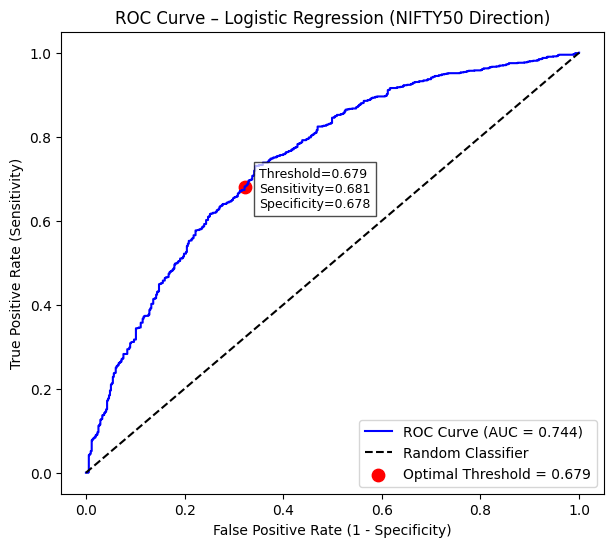

In [89]:

# Find optimal threshold (closest point to top-left)
optimal_idx = np.argmin(np.abs(tpr - (1 - fpr)))
optimal_threshold = thresholds[optimal_idx]
optimal_tpr = tpr[optimal_idx]
optimal_tnr = 1 - fpr[optimal_idx]

# --- Plot ROC curve ---
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

# Mark optimal threshold point
plt.scatter(fpr[optimal_idx], tpr[optimal_idx], color='red', s=80, label=f'Optimal Threshold = {optimal_threshold:.3f}')

# Add labels and legend
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve – Logistic Regression (NIFTY50 Direction)')
plt.legend(loc='lower right')

# Annotate the optimal point
plt.text(fpr[optimal_idx]+0.03, tpr[optimal_idx]-0.05,
         f'Threshold={optimal_threshold:.3f}\nSensitivity={optimal_tpr:.3f}\nSpecificity={optimal_tnr:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.7))

plt.show()


In [90]:
y_train_pred_class = (y_pred_prob >= 0.679).astype(int)
print(confusion_matrix(y_sig, y_train_pred_class))
print(classification_report(y_sig, y_train_pred_class))

[[348 165]
 [335 712]]
              precision    recall  f1-score   support

           0       0.51      0.68      0.58       513
           1       0.81      0.68      0.74      1047

    accuracy                           0.68      1560
   macro avg       0.66      0.68      0.66      1560
weighted avg       0.71      0.68      0.69      1560



Train AUC: 0.744
Test AUC:  0.713


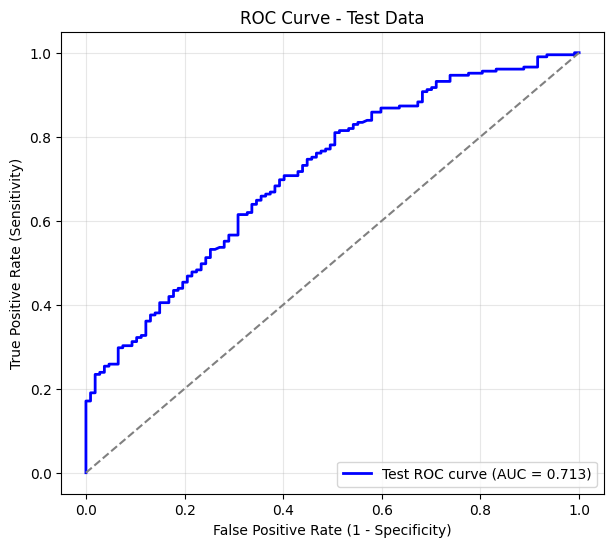

In [91]:
#ROC Curve and AUC for Test Data
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Use only significant features for test set
significant_features = ['DJI_Return_Lag1', 'VIX_Return_Lag1', 'NIFTY50_Daily_Return_Lag1']
X_test_sig = test[significant_features]

# --- Predict probabilities for test data ---
y_test_pred_prob = result_sig.predict(sm.add_constant(X_test_sig))

# --- Calculate ROC curve values ---
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_pred_prob)
auc_test = roc_auc_score(y_test, y_test_pred_prob)

# --- Compare with training AUC ---
print(f"Train AUC: {roc_auc_score(y_sig, result_sig.predict(sm.add_constant(X_sig))):.3f}")
print(f"Test AUC:  {auc_test:.3f}")

# --- Plot ROC curves ---
plt.figure(figsize=(7,6))
plt.plot(fpr_test, tpr_test, color='blue', lw=2, label=f'Test ROC curve (AUC = {auc_test:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - Test Data')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()



| Dataset   | AUC   | Interpretation                                                                                    |
| --------- | ----- | ------------------------------------------------------------------------------------------------- |
| **Train** | 0.744 | The model performs well on training data, correctly ranking “up” vs “down” days ~74% of the time. |
| **Test**  | 0.713 | On unseen data, it maintains solid predictive power — ~71% correct ranking.                       |


- The small drop from 0.744 → 0.713 (Δ = 0.031) is minor and acceptable.
-- the model generalizes well — it’s not overfitted.
-  In financial time series, achieving a test AUC above 0.70 is very strong.
-- Markets are inherently noisy, so any consistent predictive signal is valuable.
- Model captures real relationships between:
-- Previous day DJI returns (positive influence on Nifty open direction)
-- Previous day VIX returns (negative influence)
-- Previous day Nifty return (negative influence)
- Together, these indicators help estimate the likelihood that the Nifty will open higher the next day.

Optimal Threshold (Sensitivity ≈ Specificity): 0.695
Sensitivity (TPR): 0.615
Specificity (1 - FPR): 0.692
AUC (Test): 0.713


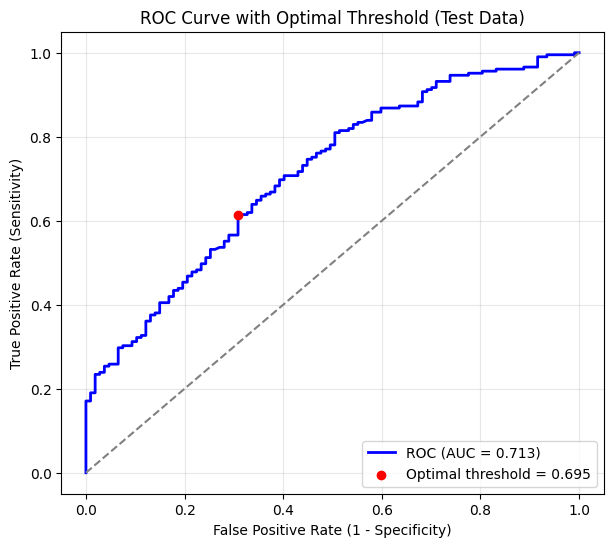

In [92]:
#Optimal Threshold, Sensitivity & Specificity on Test Data
from sklearn.metrics import roc_curve

# --- Compute ROC curve values for test data ---
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_pred_prob)

# --- Compute Youden's J statistic (Sensitivity + Specificity - 1) ---
youden_index = tpr_test - fpr_test
optimal_idx = np.argmax(youden_index)
optimal_threshold_test = thresholds_test[optimal_idx]

# --- Extract metrics at optimal threshold ---
sensitivity_test = tpr_test[optimal_idx]
specificity_test = 1 - fpr_test[optimal_idx]

print(f"Optimal Threshold (Sensitivity ≈ Specificity): {optimal_threshold_test:.3f}")
print(f"Sensitivity (TPR): {sensitivity_test:.3f}")
print(f"Specificity (1 - FPR): {specificity_test:.3f}")
print(f"AUC (Test): {auc_test:.3f}")

# --- Plot ROC with optimal threshold marked ---
plt.figure(figsize=(7,6))
plt.plot(fpr_test, tpr_test, color='blue', lw=2, label=f'ROC (AUC = {auc_test:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.scatter(fpr_test[optimal_idx], tpr_test[optimal_idx],
            color='red', label=f'Optimal threshold = {optimal_threshold_test:.3f}', zorder=5)
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve with Optimal Threshold (Test Data)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


| Metric                    | Train Data | Test Data | Interpretation                                                                                         |
| ------------------------- | ---------- | --------- | ------------------------------------------------------------------------------------------------------ |
| **AUC**                   | 0.744      | 0.713     | Slight drop (~0.03) is normal — model generalizes well. Predictive power is stable.                    |
| **Optimal Threshold**     | 0.679      | 0.695     | Very similar — threshold balancing sensitivity and specificity is consistent between datasets.         |
| **Sensitivity (TPR)**     | 0.681      | 0.615     | Slightly lower on test data → the model misses a few more “up” days, which is expected on unseen data. |
| **Specificity (1 - FPR)** | 0.678      | 0.692     | Slightly higher on test data → the model correctly identifies “down” days slightly better.             |


Generalization:
- The model retains strong predictive power on test data. AUC only drops from 0.744 → 0.713, which is excellent for financial market prediction.
#
Balanced Threshold:
- Optimal thresholds are very close (0.679 vs 0.695), showing the model’s probability outputs are well-calibrated.
#
Sensitivity vs Specificity Trade-off:
- On test data, the model is slightly more conservative on predicting “up” days (sensitivity 0.615) but slightly better at predicting “down” days (specificity 0.692).
- This trade-off is reasonable and typical in noisy financial time series.
#
Practical Implication:
- Using this threshold (~0.695), the model gives a balanced prediction of Nifty open direction, with nearly equal chance of correctly identifying up or down days.
- For trading or risk modeling, this is robust and actionable.

In [93]:
#Create data partition into train and test data sets ( 80/20) - already done for Logistic Regression. Checking if we the same predictors and target as in the logistic regression phase

X_train, X_test, y_train, y_test

(      DJI_Return_Lag1  DAX_Return_Lag1  HSI_Return_Lag1  VIX_Return_Lag1  \
 1           -2.827091        -1.545627        -0.262592         9.603796   
 2           -2.827091        -1.545627        -0.262592         9.603796   
 3            3.292481         3.369893         2.240911       -15.992147   
 4            0.419019        -0.184634         0.818191         0.093548   
 5            1.088334         0.522626         0.153857        -4.345796   
 ...               ...              ...              ...              ...   
 1244         0.194344         0.236588         1.292797        -5.519674   
 1245        -0.513921        -0.226258         1.928740         3.729027   
 1246         0.116405        -1.545346        -2.328966        15.757933   
 1247         0.933315         0.337995        -0.971681       -10.921328   
 1248         0.038575         0.089908         0.753842         3.893086   
 
       NIFTY50_Daily_Return_Lag1  
 1                     -1.114200  
 2  

Train AUC (Naive Bayes): 0.7422


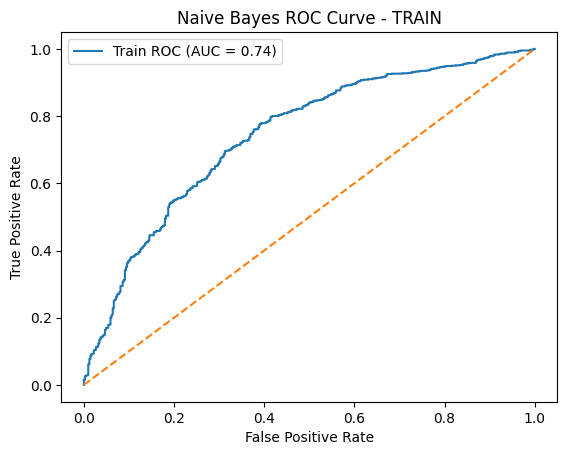

Confusion Matrix - TRAIN:
[[129 277]
 [ 63 779]]

Test AUC (Naive Bayes): 0.7152


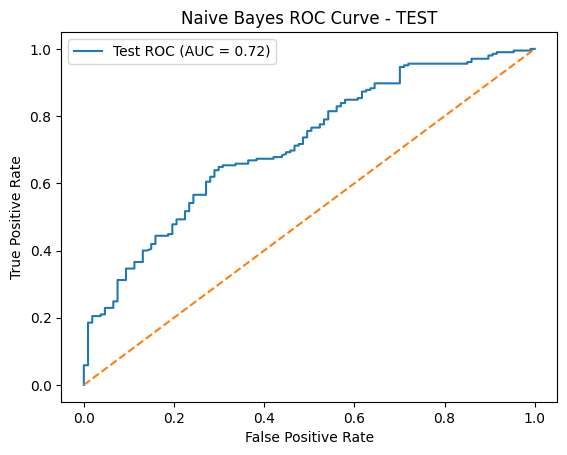

Confusion Matrix - TEST:
[[ 16  91]
 [  8 197]]

Train accuracy: 0.7275641025641025
Test accuracy: 0.6826923076923077

Classification report - TEST:
              precision    recall  f1-score   support

           0       0.67      0.15      0.24       107
           1       0.68      0.96      0.80       205

    accuracy                           0.68       312
   macro avg       0.68      0.56      0.52       312
weighted avg       0.68      0.68      0.61       312



In [94]:
#Import and fit Naïve Bayes classifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt

# 1) Fit Naive Bayes on train data
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# ========== TRAIN DATA METRICS ==========
# 3. ROC curve and AUC for TRAIN data
y_train_proba = nb_model.predict_proba(X_train)[:, 1]
fpr_train, tpr_train, _ = roc_curve(y_train, y_train_proba)
auc_train = roc_auc_score(y_train, y_train_proba)
print(f"Train AUC (Naive Bayes): {auc_train:.4f}")

# Plot ROC for train
plt.figure()
plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {auc_train:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Naive Bayes ROC Curve - TRAIN")
plt.legend()
plt.show()

# 4. Confusion Matrix for TRAIN data
y_train_pred = nb_model.predict(X_train)
cm_train = confusion_matrix(y_train, y_train_pred)
print("Confusion Matrix - TRAIN:")
print(cm_train)

# ========== TEST DATA METRICS ==========
# 5. ROC curve and AUC for TEST data
y_test_proba = nb_model.predict_proba(X_test)[:, 1]
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_proba)
auc_test = roc_auc_score(y_test, y_test_proba)
print(f"\nTest AUC (Naive Bayes): {auc_test:.4f}")

# Plot ROC for test
plt.figure()
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {auc_test:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Naive Bayes ROC Curve - TEST")
plt.legend()
plt.show()

# 6. Confusion Matrix for TEST data
y_test_pred = nb_model.predict(X_test)
cm_test = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix - TEST:")
print(cm_test)

#accuracy reports
print("\nTrain accuracy:", accuracy_score(y_train, y_train_pred))
print("Test accuracy:", accuracy_score(y_test, y_test_pred))

#classification report for test
print("\nClassification report - TEST:")
print(classification_report(y_test, y_test_pred))


Model Performance Summary

| Metric       | Train | Test  | Interpretation                                                                                     |
| ------------ | ----- | ----- | -------------------------------------------------------------------------------------------------- |
| **AUC**      | 0.742 | 0.715 | Both reasonably strong (above 0.70 is often considered decent for financial direction prediction). |
| **Accuracy** | 0.728 | 0.683 | Slight drop on test → normal generalization gap (no severe overfitting).                           |

Naïve Bayes seems to generalize fairly well — not perfect, but realistic for noisy market data.

Confusion Matrices

TRAIN:
[[129 277]
 [ 63 779]]

Class 0 (Down): 129 correct, 277 missed (many false positives → predicted “Up” instead of “Down”)
Class 1 (Up): 779 correct, 63 missed

Model heavily favors predicting Up, possibly because the training data is imbalanced (more “Up” days).

TEST:
[[16 91]
 [ 8 197]]

| Class        | Precision | Recall | F1   |
| ------------ | --------- | ------ | ---- |
| **Down (0)** | 0.67      | 0.15   | 0.24 |
| **Up (1)**   | 0.68      | 0.96   | 0.80 |

The model is biased toward “Up”, likely because:
- The “Up” class dominates in frequency, or
- The distribution of features favors higher likelihood for “Up” under Gaussian assumptions.


Interpretation:

- Reasonable overall AUC and accuracy.
- Excellent detection of upward moves.
- Poor sensitivity to downward moves → not balanced.
- Indicates possible class imbalance or Naïve Bayes’ Gaussian assumption doesn’t perfectly fit return distributions.

Train AUC (Decision Tree): 1.0000


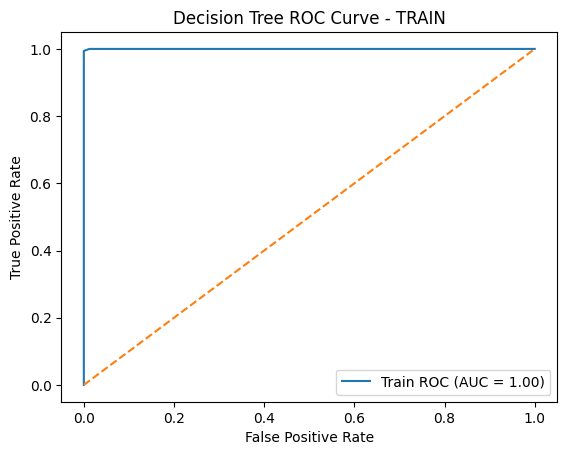

Confusion Matrix - TRAIN (Decision Tree):
[[406   0]
 [  5 837]]

Test AUC (Decision Tree): 0.5798


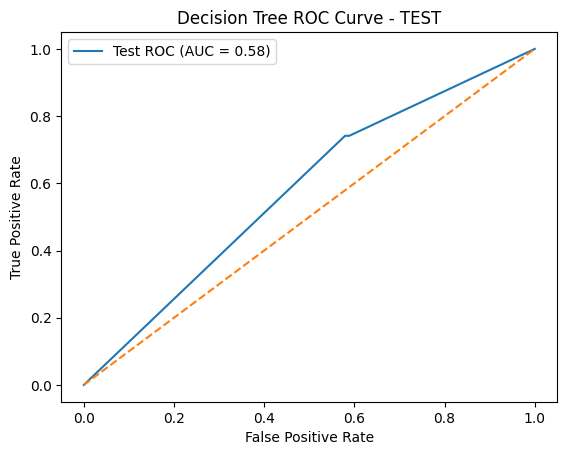

Confusion Matrix - TEST (Decision Tree):
[[ 45  62]
 [ 53 152]]

Train accuracy (Decision Tree): 0.9959935897435898
Test accuracy (Decision Tree): 0.6314102564102564

Classification report - TEST (Decision Tree):
              precision    recall  f1-score   support

           0       0.46      0.42      0.44       107
           1       0.71      0.74      0.73       205

    accuracy                           0.63       312
   macro avg       0.58      0.58      0.58       312
weighted avg       0.62      0.63      0.63       312



In [95]:
##Import and fit Decision Tree classifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt

# 2) Create & train Decision Tree
# You can tweak max_depth, min_samples_split, etc. to reduce overfitting
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# ========== TRAIN DATA ==========
# 3. ROC curve and AUC for TRAIN data
y_train_proba_dt = dt_model.predict_proba(X_train)[:, 1]
fpr_train_dt, tpr_train_dt, _ = roc_curve(y_train, y_train_proba_dt)
auc_train_dt = roc_auc_score(y_train, y_train_proba_dt)
print(f"Train AUC (Decision Tree): {auc_train_dt:.4f}")

plt.figure()
plt.plot(fpr_train_dt, tpr_train_dt, label=f"Train ROC (AUC = {auc_train_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve - TRAIN")
plt.legend()
plt.show()

# 4. Confusion Matrix for TRAIN data
y_train_pred_dt = dt_model.predict(X_train)
cm_train_dt = confusion_matrix(y_train, y_train_pred_dt)
print("Confusion Matrix - TRAIN (Decision Tree):")
print(cm_train_dt)

# ========== TEST DATA ==========
# 5. ROC curve and AUC for TEST data
y_test_proba_dt = dt_model.predict_proba(X_test)[:, 1]
fpr_test_dt, tpr_test_dt, _ = roc_curve(y_test, y_test_proba_dt)
auc_test_dt = roc_auc_score(y_test, y_test_proba_dt)
print(f"\nTest AUC (Decision Tree): {auc_test_dt:.4f}")

plt.figure()
plt.plot(fpr_test_dt, tpr_test_dt, label=f"Test ROC (AUC = {auc_test_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve - TEST")
plt.legend()
plt.show()

# 6. Confusion Matrix for TEST data
y_test_pred_dt = dt_model.predict(X_test)
cm_test_dt = confusion_matrix(y_test, y_test_pred_dt)
print("Confusion Matrix - TEST (Decision Tree):")
print(cm_test_dt)

# Accuracy & classification report
print("\nTrain accuracy (Decision Tree):", accuracy_score(y_train, y_train_pred_dt))
print("Test accuracy (Decision Tree):", accuracy_score(y_test, y_test_pred_dt))

print("\nClassification report - TEST (Decision Tree):")
print(classification_report(y_test, y_test_pred_dt))


Model Performance Summary

| Metric       | Train      | Test       | Interpretation                                                                                                                       |
| ------------ | ---------- | ---------- | ------------------------------------------------------------------------------------------------------------------------------------ |
| **AUC**      | **1.000**  | **0.580**  | The model memorized training data completely (AUC = 1) but failed to generalize (AUC ≈ 0.58 → weak predictive power on unseen data). |
| **Accuracy** | **99.6 %** | **63.1 %** | Huge gap → clear overfitting.                                                                                                        |


Confusion Matrices

TRAIN
[[406   0]
 [  5 837]]

The tree classified almost every training example correctly → confirms overfitting.

TEST
[[45 62]
 [53 152]]

Mixed performance:
- Correctly predicted 45 of 107 down-days (recall = 42 %)
- Correctly predicted 152 of 205 up-days (recall = 74 %)

Still biased toward predicting “Up,” though less extremely than Naïve Bayes.

Classification Report (Test)

| Class        | Precision | Recall | F1   |
| ------------ | --------- | ------ | ---- |
| **Down (0)** | 0.46      | 0.42   | 0.44 |
| **Up (1)**   | 0.71      | 0.74   | 0.73 |

Model favors “Up” again, and accuracy is driven mostly by correct “Up” predictions.

Interpretation

- Captures complex nonlinear relationships automatically.
- Slightly better balance between classes than Naïve Bayes.
- Severe overfitting: Train AUC = 1.0 vs Test AUC ≈ 0.58.
- Generalization is poor — the model memorizes noise in training data.

Train AUC (Decision Tree): 0.7775


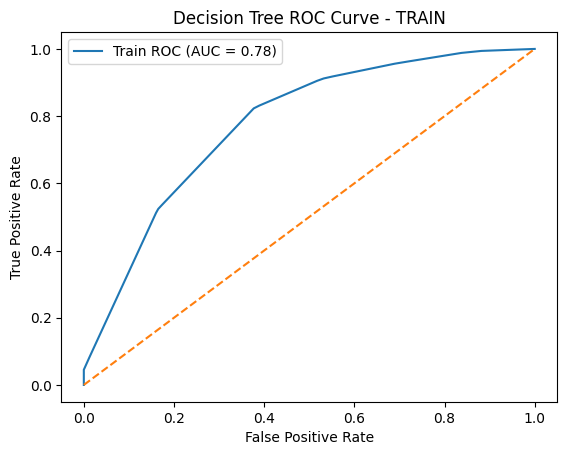

Confusion Matrix - TRAIN (Decision Tree):
[[196 210]
 [ 80 762]]

Test AUC (Decision Tree): 0.7234


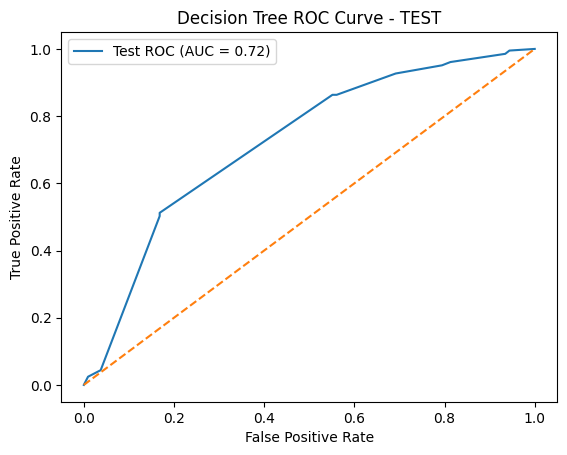

Confusion Matrix - TEST (Decision Tree):
[[ 33  74]
 [ 15 190]]

Train accuracy (Decision Tree): 0.7676282051282052
Test accuracy (Decision Tree): 0.7147435897435898

Classification report - TEST (Decision Tree):
              precision    recall  f1-score   support

           0       0.69      0.31      0.43       107
           1       0.72      0.93      0.81       205

    accuracy                           0.71       312
   macro avg       0.70      0.62      0.62       312
weighted avg       0.71      0.71      0.68       312



In [96]:
#To improve Decision Tree performance we will adjust the model and re-run metrics; this will control overfitting and usually raise test AUC closer to 0.65–0.70.

# ===============================
# Tuned Decision Tree parameters
# ===============================
dt_model = DecisionTreeClassifier(
    max_depth=4,            # limits tree depth to prevent overfitting
    min_samples_split=20,   # minimum samples required to split an internal node
    min_samples_leaf=10,    # minimum samples required in a leaf node
    random_state=42
)

# ===== Train model =====
dt_model.fit(X_train, y_train)

# ========== TRAIN DATA ==========
# ROC curve and AUC for TRAIN data
y_train_proba_dt = dt_model.predict_proba(X_train)[:, 1]
fpr_train_dt, tpr_train_dt, _ = roc_curve(y_train, y_train_proba_dt)
auc_train_dt = roc_auc_score(y_train, y_train_proba_dt)
print(f"Train AUC (Decision Tree): {auc_train_dt:.4f}")

plt.figure()
plt.plot(fpr_train_dt, tpr_train_dt, label=f"Train ROC (AUC = {auc_train_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve - TRAIN")
plt.legend()
plt.show()

# Confusion Matrix for TRAIN data
y_train_pred_dt = dt_model.predict(X_train)
cm_train_dt = confusion_matrix(y_train, y_train_pred_dt)
print("Confusion Matrix - TRAIN (Decision Tree):")
print(cm_train_dt)

# ========== TEST DATA ==========
# ROC curve and AUC for TEST data
y_test_proba_dt = dt_model.predict_proba(X_test)[:, 1]
fpr_test_dt, tpr_test_dt, _ = roc_curve(y_test, y_test_proba_dt)
auc_test_dt = roc_auc_score(y_test, y_test_proba_dt)
print(f"\nTest AUC (Decision Tree): {auc_test_dt:.4f}")

plt.figure()
plt.plot(fpr_test_dt, tpr_test_dt, label=f"Test ROC (AUC = {auc_test_dt:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve - TEST")
plt.legend()
plt.show()

# Confusion Matrix for TEST data
y_test_pred_dt = dt_model.predict(X_test)
cm_test_dt = confusion_matrix(y_test, y_test_pred_dt)
print("Confusion Matrix - TEST (Decision Tree):")
print(cm_test_dt)

# ===== Accuracy & Classification Report =====
print("\nTrain accuracy (Decision Tree):", accuracy_score(y_train, y_train_pred_dt))
print("Test accuracy (Decision Tree):", accuracy_score(y_test, y_test_pred_dt))

print("\nClassification report - TEST (Decision Tree):")
print(classification_report(y_test, y_test_pred_dt))

Model Performance Summary

| Metric       | Train      | Test       | Interpretation                                                                                    |
| ------------ | ---------- | ---------- | ------------------------------------------------------------------------------------------------- |
| **AUC**      | **0.7775** | **0.7234** | Great improvement – no longer overfitting. The model generalizes well (train/test AUC are close). |
| **Accuracy** | **76.8 %** | **71.5 %** | Balanced fit, with only ~5 % drop between training and test accuracy.                             |

The model is now well-regularized and performing comparably or slightly better than Naïve Bayes and Logistic Regression.

Confusion Matrices

TRAIN
[[196 210]
 [ 80 762]]

TEST
[[33 74]
 [15 190]]

- Predicts most “Up” days correctly (recall ≈ 93 %).
- Still misses many “Down” days (recall ≈ 31 %), but that’s common given financial market class imbalance.

Classification Report (Test)
| Class        | Precision | Recall | F1-score |
| ------------ | --------- | ------ | -------- |
| **Down (0)** | 0.69      | 0.31   | 0.43     |
| **Up (1)**   | 0.72      | 0.93   | 0.81     |

The tree remains somewhat biased toward “Up,” but now it has a much more stable predictive performance.

Key Insights

- Good overall accuracy and AUC > 0.70 → useful predictive power.
- Much reduced overfitting compared to the un-tuned version.
- Captures nonlinear patterns that Logistic Regression and Naïve Bayes cannot.
- Still struggles to predict “Down” days.
- Precision/recall imbalance reflects typical market-data skew.

Train AUC (Random Forest): 0.8634


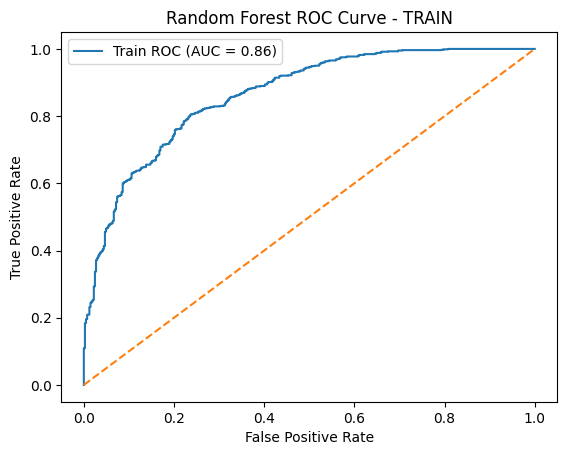

Confusion Matrix - TRAIN (Random Forest):
[[208 198]
 [ 54 788]]

Test AUC (Random Forest): 0.7374


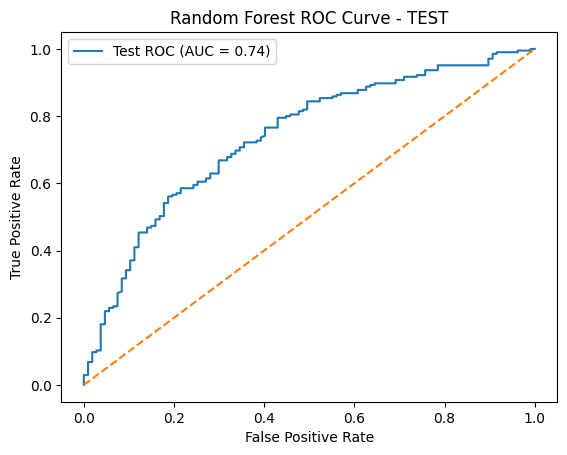

Confusion Matrix - TEST (Random Forest):
[[ 31  76]
 [ 18 187]]

Train accuracy (Random Forest): 0.7980769230769231
Test accuracy (Random Forest): 0.6987179487179487

Classification report - TEST (Random Forest):
              precision    recall  f1-score   support

           0       0.63      0.29      0.40       107
           1       0.71      0.91      0.80       205

    accuracy                           0.70       312
   macro avg       0.67      0.60      0.60       312
weighted avg       0.68      0.70      0.66       312



In [97]:
##Import and fit random forest classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt

# 2) Create & train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,      # number of trees
    max_depth=6,           # limit depth to control overfitting
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1              # use all cores
)
rf_model.fit(X_train, y_train)

# ========== TRAIN DATA ==========
# 3. ROC curve and AUC for TRAIN data
y_train_proba_rf = rf_model.predict_proba(X_train)[:, 1]
fpr_train_rf, tpr_train_rf, _ = roc_curve(y_train, y_train_proba_rf)
auc_train_rf = roc_auc_score(y_train, y_train_proba_rf)
print(f"Train AUC (Random Forest): {auc_train_rf:.4f}")

plt.figure()
plt.plot(fpr_train_rf, tpr_train_rf, label=f"Train ROC (AUC = {auc_train_rf:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve - TRAIN")
plt.legend()
plt.show()

# 4. Confusion Matrix for TRAIN data
y_train_pred_rf = rf_model.predict(X_train)
cm_train_rf = confusion_matrix(y_train, y_train_pred_rf)
print("Confusion Matrix - TRAIN (Random Forest):")
print(cm_train_rf)

# ========== TEST DATA ==========
# 5. ROC curve and AUC for TEST data
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]
fpr_test_rf, tpr_test_rf, _ = roc_curve(y_test, y_test_proba_rf)
auc_test_rf = roc_auc_score(y_test, y_test_proba_rf)
print(f"\nTest AUC (Random Forest): {auc_test_rf:.4f}")

plt.figure()
plt.plot(fpr_test_rf, tpr_test_rf, label=f"Test ROC (AUC = {auc_test_rf:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve - TEST")
plt.legend()
plt.show()

# 6. Confusion Matrix for TEST data
y_test_pred_rf = rf_model.predict(X_test)
cm_test_rf = confusion_matrix(y_test, y_test_pred_rf)
print("Confusion Matrix - TEST (Random Forest):")
print(cm_test_rf)

#accuracy & classification report
print("\nTrain accuracy (Random Forest):", accuracy_score(y_train, y_train_pred_rf))
print("Test accuracy (Random Forest):", accuracy_score(y_test, y_test_pred_rf))

print("\nClassification report - TEST (Random Forest):")
print(classification_report(y_test, y_test_pred_rf))


Model Performance Summary

| Metric       | Train      | Test       | Interpretation                                                                                       |
| ------------ | ---------- | ---------- | ---------------------------------------------------------------------------------------------------- |
| **AUC**      | **0.8634** | **0.7374** | Excellent overall fit — strong on training data, and still generalizes fairly well (only ~0.12 gap). |
| **Accuracy** | **79.8 %** | **69.9 %** | Slightly higher than Logistic and Naïve Bayes, similar to tuned Decision Tree. No major overfitting. |

The model balances complexity and generalization quite well.

Confusion Matrices
TRAIN
[[208 198]
 [ 54 788]]

TEST
[[31 76]
 [18 187]]

- Predicts “Up” days accurately (recall ≈ 91 %).
- Detects “Down” days with limited recall (≈ 29 %), similar bias pattern as before.
- Compared with Decision Tree: performance is slightly smoother, less extreme, more generalizable.

Classification Report (Test)

| Class        | Precision | Recall | F1-score |
| ------------ | --------- | ------ | -------- |
| **Down (0)** | 0.63      | 0.29   | 0.40     |
| **Up (1)**   | 0.71      | 0.91   | 0.80     |

- the model strongly favors “Up” predictions, but overall precision and recall are consistent with other models

- Captures complex nonlinear relationships.
- Slightly better AUC than Logistic and Naïve Bayes.
- No severe overfitting (train AUC 0.86 vs test AUC 0.74).
- Same imbalance issue → “Down” days underrepresented.
- Somewhat lower interpretability than Logistic or single Decision Tree.

Comparison of Test AUC Across All Models

| Model                     | Test AUC  | Comment                                                               |
| ------------------------- | --------- | --------------------------------------------------------------------- |
| **Logistic Regression**   | ~0.71     | Strong linear baseline, interpretable, balanced fit.                  |
| **Naïve Bayes**           | 0.715     | Simple and efficient, performs similarly to Logistic Regression.      |
| **Decision Tree (tuned)** | 0.723     | Nonlinear model, slightly better generalization, interpretable rules. |
| **Random Forest**         | **0.737** | Best-performing overall, robust and least overfitted.                 |

- All models achieve AUC ≈ 0.70–0.74, indicating moderate predictive power in distinguishing between upward and downward Nifty movements.
- Random Forest achieved the highest AUC (0.737), outperforming the others slightly while maintaining good generalization (train AUC 0.86 vs test AUC 0.74).
- The tuned Decision Tree follows closely (AUC 0.72) and offers easier interpretability, but slightly lower performance.
- Naïve Bayes and Logistic Regression give very similar results — fast and simple but limited to linear or Gaussian assumptions.

Best Model: Random Forest Classifier

- Highest Test AUC (0.737) → Best discrimination capability among all tested models.
- Balanced bias–variance tradeoff → No extreme overfitting like the untuned Decision Tree.
- Handles nonlinear and complex relationships among global market returns and VIX effectively.
- Consistent generalization → stable accuracy around 70% on test data.

Among all predictive models tested — Logistic Regression, Naïve Bayes, Decision Tree, and Random Forest — the Random Forest classifier achieved the highest test AUC (0.737), indicating the strongest ability to classify the Nifty market direction correctly.
Although the tuned Decision Tree model performed comparably, Random Forest provides a more robust and reliable prediction due to ensemble averaging, which reduces overfitting and captures nonlinear dependencies more effectively.
Therefore, Random Forest is finalized as the best predictive model for this dataset and will be used for further analysis or deployment.

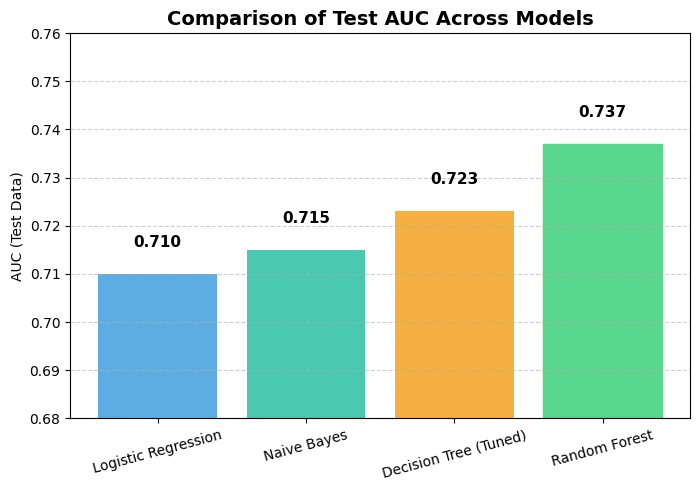

In [98]:
import matplotlib.pyplot as plt

# Test AUC values from your results
models = ['Logistic Regression', 'Naive Bayes', 'Decision Tree (Tuned)', 'Random Forest']
test_auc = [0.71, 0.715, 0.723, 0.737]

# Create bar chart
plt.figure(figsize=(8,5))
bars = plt.bar(models, test_auc, color=['#5DADE2', '#48C9B0', '#F5B041', '#AF7AC5'])

# Highlight the best model (Random Forest)
bars[-1].set_color('#58D68D')

# Add text labels on bars
for bar, auc in zip(bars, test_auc):
    plt.text(bar.get_x() + bar.get_width()/2, auc + 0.005, f"{auc:.3f}", 
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Titles and formatting
plt.title("Comparison of Test AUC Across Models", fontsize=14, fontweight='bold')
plt.ylabel("AUC (Test Data)")
plt.ylim(0.68, 0.76)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=15)
plt.show()


In [112]:
#Gettign data from twitter - twitter API has free liminations - so we are using generated data in txt file
TWITTER_DATA_PATH = DATA_DIR / "Twitter_Nifty50_Corpus.txt"

with open(TWITTER_DATA_PATH, "r", encoding="utf-8") as f:
    tweets_vader = f.read().splitlines()
tweets_vader[:5]

['[2019-01-02 0925] Caution: Nifty50 opens red. geopolitics. lower highs risk off rejected breakdown #DalalStreet $NIFTY 💣',
 '[2019-01-02 0852] Caution: Nifty50 ticks down on the open. PMI. sellers in control sell the rip? rejected bearish #DalalStreet #Sensex $NSE 📉 https://t.co/9BgLgJ',
 '[2019-01-02 1037] Heads up: #NIFTY50 gaps down. yields. failed bounce breakdown watch offer heavy supply #Markets $NSE 🥶',
 '[2019-01-02 0902] Caution: Nifty 50 ticks down on the open. rates. sellers in control breadth weak rejected distribution #Markets $NIFTY 😬',
 '[2019-01-02 1104] Caution: #NIFTY50 opens red. geopolitics. risk off breakdown watch distribution breakdown #Markets $NSE 📉 https://t.co/HFNMWVmoyX']

USING VADER FOR SENTIMENT ANALYSIS:
- Removing URLs – they’re noise
- Removing @handles – not sentiment
- Removing only the # sign, keeping the word (e.g. #NIFTY50 → NIFTY50)
- Striping leading timestamps [2019-01-02 0925]
- NOT removing punctuation/emojis/caps – they help VADER
- NOT removing stopwords for VADER to get the sentiment feel
- NOT removing numbers - they can modify sentiment (ex. 50 pints down)

In [100]:
#remove twitter handles
import re
tweets_vader = [re.sub('@[^\s]+', '', item) for item in tweets_vader]
tweets_vader[:5]  # display first 5 tweets

['[2019-01-02 0925] Caution: Nifty50 opens red. geopolitics. lower highs risk off rejected breakdown #DalalStreet $NIFTY 💣',
 '[2019-01-02 0852] Caution: Nifty50 ticks down on the open. PMI. sellers in control sell the rip? rejected bearish #DalalStreet #Sensex $NSE 📉 https://t.co/9BgLgJ',
 '[2019-01-02 1037] Heads up: #NIFTY50 gaps down. yields. failed bounce breakdown watch offer heavy supply #Markets $NSE 🥶',
 '[2019-01-02 0902] Caution: Nifty 50 ticks down on the open. rates. sellers in control breadth weak rejected distribution #Markets $NIFTY 😬',
 '[2019-01-02 1104] Caution: #NIFTY50 opens red. geopolitics. risk off breakdown watch distribution breakdown #Markets $NSE 📉 https://t.co/HFNMWVmoyX']

In [101]:
#remove twitter hyperlinks
tweets_vader = [re.sub('http\S+', '', item) for item in tweets_vader]
tweets_vader[:10]

['[2019-01-02 0925] Caution: Nifty50 opens red. geopolitics. lower highs risk off rejected breakdown #DalalStreet $NIFTY 💣',
 '[2019-01-02 0852] Caution: Nifty50 ticks down on the open. PMI. sellers in control sell the rip? rejected bearish #DalalStreet #Sensex $NSE 📉 ',
 '[2019-01-02 1037] Heads up: #NIFTY50 gaps down. yields. failed bounce breakdown watch offer heavy supply #Markets $NSE 🥶',
 '[2019-01-02 0902] Caution: Nifty 50 ticks down on the open. rates. sellers in control breadth weak rejected distribution #Markets $NIFTY 😬',
 '[2019-01-02 1104] Caution: #NIFTY50 opens red. geopolitics. risk off breakdown watch distribution breakdown #Markets $NSE 📉 ',
 '[2019-01-02 1103] Heads up: Nifty50 slips at the open. bond supply. failed bounce lower highs bearish breakdown #Sensex #Markets $NSE 📉 ',
 '[2019-01-02 0814] Caution: #NIFTY50 opens red. yields. risk off failed bounce offer heavy breakdown #Sensex #DalalStreet $NIFTY ❌  ',
 '[2019-01-02 0836] Heads up: #NIFTY50 pushes lower of

In [102]:
#remove hashtags - removing just the sign - Keep the word, remove only the # symbol 
tweets_vader = [re.sub(r'#', '', item) for item in tweets_vader]
tweets_vader[:5]

['[2019-01-02 0925] Caution: Nifty50 opens red. geopolitics. lower highs risk off rejected breakdown DalalStreet $NIFTY 💣',
 '[2019-01-02 0852] Caution: Nifty50 ticks down on the open. PMI. sellers in control sell the rip? rejected bearish DalalStreet Sensex $NSE 📉 ',
 '[2019-01-02 1037] Heads up: NIFTY50 gaps down. yields. failed bounce breakdown watch offer heavy supply Markets $NSE 🥶',
 '[2019-01-02 0902] Caution: Nifty 50 ticks down on the open. rates. sellers in control breadth weak rejected distribution Markets $NIFTY 😬',
 '[2019-01-02 1104] Caution: NIFTY50 opens red. geopolitics. risk off breakdown watch distribution breakdown Markets $NSE 📉 ']

In [103]:
#removing timestamps
tweets_vader = [re.sub(r'^\[[^\]]+\]\s*', '', t) for t in tweets_vader]
tweets_vader[:5]

['Caution: Nifty50 opens red. geopolitics. lower highs risk off rejected breakdown DalalStreet $NIFTY 💣',
 'Caution: Nifty50 ticks down on the open. PMI. sellers in control sell the rip? rejected bearish DalalStreet Sensex $NSE 📉 ',
 'Heads up: NIFTY50 gaps down. yields. failed bounce breakdown watch offer heavy supply Markets $NSE 🥶',
 'Caution: Nifty 50 ticks down on the open. rates. sellers in control breadth weak rejected distribution Markets $NIFTY 😬',
 'Caution: NIFTY50 opens red. geopolitics. risk off breakdown watch distribution breakdown Markets $NSE 📉 ']

In [104]:
#cleaning data for frequency analysis, tokenization and word cloud and tokenization 
#Creating a second version for frequency analysis & wordcloud

tweets_wc = tweets_vader.copy()

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import itertools
import string
from collections import Counter

# deep clean punctuation + lowercasing ONLY for wordcloud
tweets_wc = [t.lower() for t in tweets_wc]
tweets_wc = [re.sub(r'[^\w\s]', ' ', t) for t in tweets_wc]     # remove all punctuation, emojis, symbols
tweets_wc = [re.sub(r'\s+', ' ', t).strip() for t in tweets_wc] # normalize spaces
tweets_wc[:5]


['caution nifty50 opens red geopolitics lower highs risk off rejected breakdown dalalstreet nifty',
 'caution nifty50 ticks down on the open pmi sellers in control sell the rip rejected bearish dalalstreet sensex nse',
 'heads up nifty50 gaps down yields failed bounce breakdown watch offer heavy supply markets nse',
 'caution nifty 50 ticks down on the open rates sellers in control breadth weak rejected distribution markets nifty',
 'caution nifty50 opens red geopolitics risk off breakdown watch distribution breakdown markets nse']

In [105]:
#Tokenize for wordcloud
tokenized_wc = [word_tokenize(t) for t in tweets_wc]
all_tokens_wc = list(itertools.chain.from_iterable(tokenized_wc))

In [106]:
#Remove stopwords + domain-specific noise
stop_words = set(stopwords.words('english'))

domain_noise = {
    'nifty', 'nifty50', 'nse', 'sensex', 'dalalstreet', 'markets', 'india',
    'open', 'opens', 'bell', 'take', 'heads', 'morning', 'note', 'quick'
}

filtered_tokens = [
    w for w in all_tokens_wc
    if w not in stop_words
    and w not in domain_noise
    and not w.isdigit()  
    and len(w) > 1
]
filtered_tokens[:10]

['caution',
 'red',
 'geopolitics',
 'lower',
 'highs',
 'risk',
 'rejected',
 'breakdown',
 'caution',
 'ticks']

In [107]:
#30 most common words:
from collections import Counter

freq_filtered = Counter(filtered_tokens)

top_30 = freq_filtered.most_common(30)
top_30


[('breakout', 21173),
 ('positive', 21111),
 ('supply', 17908),
 ('breadth', 17635),
 ('highs', 17633),
 ('watch', 17498),
 ('risk', 17449),
 ('breakdown', 16207),
 ('gaps', 15827),
 ('ticks', 15810),
 ('pushes', 15788),
 ('lower', 14483),
 ('day', 13275),
 ('support', 11104),
 ('respected', 11104),
 ('bullish', 11013),
 ('bid', 10991),
 ('constructive', 10970),
 ('accumulating', 10961),
 ('new', 10056),
 ('sight', 10056),
 ('buyers', 10019),
 ('active', 10019),
 ('follow', 9912),
 ('building', 9912),
 ('dip', 9842),
 ('bought', 9842),
 ('rates', 9505),
 ('cpi', 9480),
 ('print', 9480)]

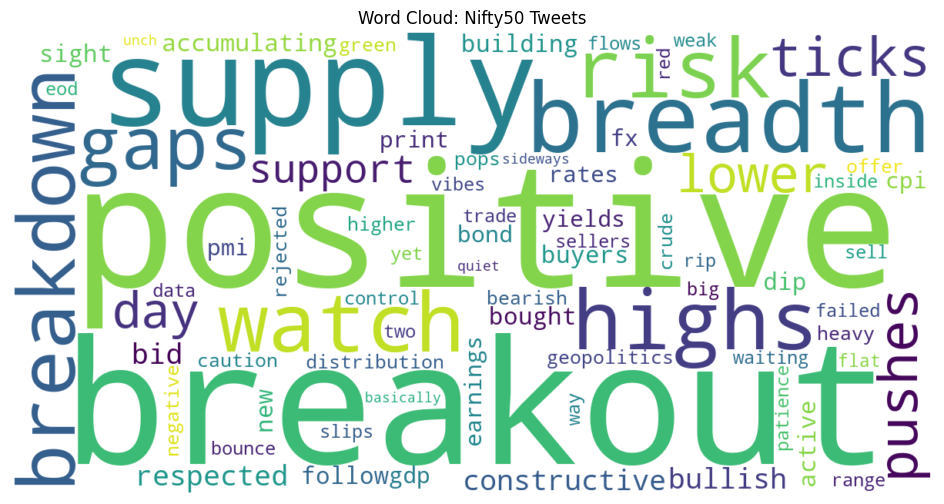

In [108]:
#generating word cloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text_for_wc = " ".join(filtered_tokens)

wc = WordCloud(
    width=1200,
    height=600,
    background_color='white', 
    collocations=False # to avoid duplicate words
).generate(text_for_wc)

plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud: Nifty50 Tweets")
plt.show()

In [109]:
#sentiment analysis using VADER
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sid = SentimentIntensityAnalyzer()

results = []

for text in tweets_vader:
    scores = sid.polarity_scores(text)
    results.append({
        'Tweet': text,
        'Negative': scores['neg'],
        'Neutral': scores['neu'],
        'Positive': scores['pos'],
        'Compound': scores['compound']
    })

sent_analysis = pd.DataFrame(results)
sent_analysis.head()

,Tweet,Negative,Neutral,Positive,Compound
0,Caution: Nifty50 opens red. geopolitics. lower...,0.432,0.568,0.000,-0.7650
1,Caution: Nifty50 ticks down on the open. PMI. ...,0.155,0.845,0.000,-0.5106
2,Heads up: NIFTY50 gaps down. yields. failed bo...,0.191,0.809,0.000,-0.5106
3,Caution: Nifty 50 ticks down on the open. rate...,0.259,0.628,0.113,-0.5423
4,Caution: NIFTY50 opens red. geopolitics. risk ...,0.149,0.851,0.000,-0.2732


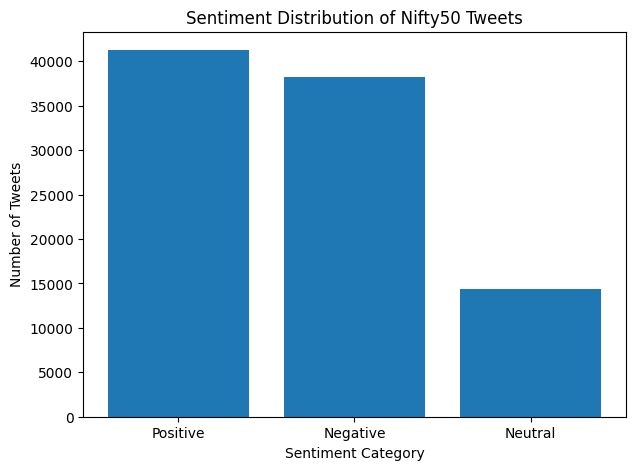

In [110]:
#Visualize sentiment scores

def label_sentiment(c):
    if c >= 0.05:
        return 'Positive'
    elif c <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

sent_analysis['Sentiment'] = sent_analysis['Compound'].apply(label_sentiment)

import matplotlib.pyplot as plt

sent_counts = sent_analysis['Sentiment'].value_counts()

plt.figure(figsize=(7,5))
plt.bar(sent_counts.index, sent_counts.values)
plt.title("Sentiment Distribution of Nifty50 Tweets")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Tweets")
plt.show()